#MOGP LMC/ICM

In [1]:
import os
import sys
from pathlib import Path

# Project root first so "src" and project modules are importable
base_path = Path("/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn")
if str(base_path) not in sys.path:
    sys.path.insert(0, str(base_path))
os.chdir(base_path)

# SUMO env
os.environ["SUMO_HOME"] = "/Library/Frameworks/EclipseSUMO.framework/Versions/1.24.0/EclipseSUMO/share/sumo"
os.environ["LIBSUMO_AS_TRACI"] = "1"
SUMO_HOME = Path(os.environ["SUMO_HOME"])
if "SUMO_HOME" in os.environ:
    tools = os.path.join(os.environ["SUMO_HOME"], "tools")
    sys.path.append(tools)
else:
    sys.exit("Please declare the environment variable 'SUMO_HOME'")

SUMO_ROOT = Path(os.environ["SUMO_HOME"]).parents[1]
SUMO_BIN = str(SUMO_ROOT / "bin")
LIB_SUMO_PATH = Path(os.environ["SUMO_HOME"]).parents[2] / "lib" / "libsumo.dylib"
os.environ["PATH"] = SUMO_BIN + os.pathsep + os.environ.get("PATH", "")

import json
import shutil
import pprint
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import seaborn as sns
import traci
import sumolib

from botorch.acquisition import ExpectedImprovement
from botorch.optim import optimize_acqf
from botorch.utils.transforms import normalize, unnormalize
from botorch.fit import fit_gpytorch_mll
from MOGP.helpers_MOGP import initialize_icm_gp, LinearAggregationICM
from src.simulation.data_loader import load_kwargs_config
from src.utils.seed import set_seed
from src.simulation.data_loader import od_xml_to_df
from src.simulation.sumo_runner import create_taz_xml, simulate_od, parse_loop_data_xml_to_pandas
from src.utils.link_flow_analysis import compute_squared_metric_per_edge

%matplotlib inline




/Library/Frameworks/EclipseSUMO.framework/Versions/1.24.0/EclipseSUMO/share/sumo/tools/traci/__init__.py:42: UserWarning: Could not import libsumo using /Users/inesbenhamza/Downloads/Sumo_od_calibration 2/env/bin/python, falling back to pure python traci (No module named 'libsumo').
  warnings.warn("Could not import libsumo using %s, falling back to pure python traci (%s)." %
/Users/inesbenhamza/Downloads/Sumo_od_calibration 2/env/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
config = load_kwargs_config(base_path, "bo_vanilla")
Path(config["simulation_run_path"]).mkdir(parents=True, exist_ok=True)
pprint.pprint(dict(config))

{'BATCH_SIZE': 1,
 'BO_batch_size': 1,
 'BO_niter': 100,
 'BO_num_restarts': 10,
 'BO_raw_samples': 128,
 'BO_sample_shape': 128,
 'CLEANUP_INTERMEDIATE_FILES': True,
 'EARLY_STOP_DELTA': 0.001,
 'EARLY_STOP_MIN_ACQ': 0.0,
 'EARLY_STOP_PATIENCE': 10,
 'EDGE_OUT_STR': 'edge_data_quickstart.xml',
 'NITER': 100,
 'NUM_RESTARTS': 10,
 'RAW_SAMPLES': 128,
 'SAMPLE_SHAPE': 128,
 'SUMO_PATH': PosixPath('/Library/Frameworks/EclipseSUMO.framework/Versions/1.24.0/EclipseSUMO/share/sumo'),
 'TRIPS2ODS_OUT_STR': 'trips.xml',
 'additional_xml': PosixPath('/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/network/quickstart/additional.xml'),
 'dim_od': 4,
 'file_gt_od': PosixPath('/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/network/quickstart/od.xml'),
 'fixed_routes': PosixPath('/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/network/quickstart/routes.csv'),
 'kernel': 'matern-2p5',
 'model_name': 'bo_vanilla',
 'n_init_search': 10,
 'net_xml': PosixPath('/Users/inesbenhamza/Desktop/Sumo

# create GT scenario 

In [3]:
# Get Ground Truth OD + fixed routes
print(f"Reading: {config['file_gt_od']}") #"/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/network/quickstart/od.xml"
gt_od_df = od_xml_to_df(config["file_gt_od"])

print(f"Reading: {config['fixed_routes']}")
routes_df = pd.read_csv(config["fixed_routes"], index_col=0)

Reading: /Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/network/quickstart/od.xml
Total GT demand: 2800.0
Reading: /Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/network/quickstart/routes.csv


In [4]:
# gt

simulation_gt_run_path =f'{config["simulation_run_path"]}/ground_truth' 
prefix_output_gt = f'{simulation_gt_run_path}/sim'
sim_edge_out_gt = f'{prefix_output_gt}_{config["EDGE_OUT_STR"]}'
new_od_xml = f'{simulation_gt_run_path}/od.xml'

Path(simulation_gt_run_path).mkdir(parents=True, exist_ok=True)

base_od = gt_od_df.copy()
gt_od_vals = gt_od_df['count'].astype(float).to_numpy()
curr_od = gt_od_vals.copy()
base_od['count'] = curr_od
base_od = base_od.rename(columns={'fromTaz':'from', 'toTaz':'to'})
create_taz_xml(new_od_xml, base_od, config["od_duration_sec"], base_path)

print(base_od)


# Run simulation
simulate_od(new_od_xml,
            prefix_output_gt,
            base_path,
            config["net_xml"],
            config["taz2edge_xml"],
            config["additional_xml"],
            routes_df,
            config["sim_end_time"],
            config["TRIPS2ODS_OUT_STR"]) 

Created /Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/output/quickstart_bo_vanilla_matern-2p5/ground_truth/od.xml
    from     to  count
0  taz91  taz93  500.0
1  taz91  taz94  500.0
2  taz92  taz93  900.0
3  taz92  taz94  900.0
od2trips --spread.uniform --taz-files /Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/network/quickstart/taz.xml --tazrelation-files output/quickstart_bo_vanilla_matern-2p5/ground_truth/od.xml --seed 0 -o /Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/output/quickstart_bo_vanilla_matern-2p5/ground_truth/sim_trips_beforeRteUpdates.xml
Running SUMO: sumo --output-prefix output/quickstart_bo_vanilla_matern-2p5/ground_truth/sim_ --ignore-route-errors=true --net-file=/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/network/quickstart/net.xml --routes=/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/output/quickstart_bo_vanilla_matern-2p5/ground_truth/sim_trips.xml -b 0 -e 57600 --additional-files /Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/net

In [5]:
df_edge_gt, df_trips_raw, out_csv = parse_loop_data_xml_to_pandas(
    base_path,
    sim_edge_out_gt,   # '.../ground_truth/sim_edge_data_quickstart.xml'
    prefix_output_gt,  # '.../ground_truth/sim'
    config["SUMO_PATH"],
)

print(df_edge_gt.head(15))
print(df_trips_raw.columns)

num_gt_edges = df_edge_gt.shape[0]
print("Number of GT edges:",num_gt_edges)


   edge_id  interval_nVehContrib  interval_harmonicMeanSpeed
0       D2                1000.0                    8.445000
1       D4                1800.0                    8.527143
2       D5                1400.0                   11.488750
3       D7                1400.0                   11.294444
4      L10                1400.0                   11.441250
5      L12                1000.0                   11.410000
6      L14                1800.0                   11.386250
7      L15                 500.0                   12.054000
8      L16                 900.0                   11.863750
9      L18                1400.0                   11.635000
10      L2                1000.0                   10.498000
11      L4                1800.0                    9.915000
12      L5                1400.0                   11.353750
13      L7                1400.0                   11.046667
Index(['interval_begin', 'interval_end', 'interval_id', 'edge_arrived',
       'edge_

# grouping the edges 

In [6]:
from src.utils.edge_flow_grouping import (
    get_representative_edges,
    group_edge_dataframe,
)

# Group ALL edges first, then get representative edge IDs
gt_edge_grouped = group_edge_dataframe(df_edge_gt)
edge_ids = get_representative_edges()

# Pull out the ground-truth flow values for the representative edges
gt_flows = gt_edge_grouped.set_index("edge_id").loc[edge_ids, "interval_nVehContrib"].values.astype(float)

print(gt_edge_grouped)

L = len(edge_ids)   # 6 groups
weights_np = np.ones(L) / L

print("Using uniform weights:")
for e, w in zip(edge_ids, weights_np):
    print(f"  {e}: weight = {w:.4f}")


  edge_id  interval_nVehContrib
0     L12                1000.0
1     L14                1800.0
2     L18                1400.0
3     L10                1400.0
4     L15                 500.0
5     L16                 900.0
Using uniform weights:
  L12: weight = 0.1667
  L14: weight = 0.1667
  L18: weight = 0.1667
  L10: weight = 0.1667
  L15: weight = 0.1667
  L16: weight = 0.1667


In [7]:
print ("GT flows :", gt_flows[:])
print ("Weights :", weights_np[:])

GT flows : [1000. 1800. 1400. 1400.  500.  900.]
Weights : [0.16666667 0.16666667 0.16666667 0.16666667 0.16666667 0.16666667]


## initial training data

In [7]:
from typing import Any

csv_path = Path("output/quickstart_bo_vanilla_matern-2p5/initial_search/squared/data_set_ods_10_squared.csv")

if not csv_path.exists():
    raise FileNotFoundError(
        f"Initial data not found at {csv_path}. "
        "Run the initial search (Sobol + simulations) once and save to this path, or use the full block with the else branch."
    )

print(f"Loading initial data from {csv_path}")
df_initial_bo = pd.read_csv(csv_path)

x_cols = [col for col in df_initial_bo.columns if col.startswith("x_")]
x_cols.sort(key=lambda x: int(x.split("_")[1]))
e_cols = [col for col in df_initial_bo.columns if col.startswith("e_")]

train_X_list = []
train_E_list = []
S_list = []

for _, row in df_initial_bo.iterrows():
    train_X_list.append(row[x_cols].values.astype(float))
    train_E_list.append(row[e_cols].values.astype(float))
    S_list.append(float(row["loss"]))

print(f"  Loaded {len(train_X_list)} initial points")
print(f"  OD dimension: {len(x_cols)}, Edges: {len(e_cols)}")

Loading initial data from output/quickstart_bo_vanilla_matern-2p5/initial_search/squared/data_set_ods_10_squared.csv
  Loaded 10 initial points
  OD dimension: 4, Edges: 6


In [28]:
# setting devices and dtype

In [8]:
dtype  = torch.double
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
dim_od= config["dim_od"]




# free flow and congestion 

In [18]:
import importlib
import src.simulation.initial_sampling as initial_sampling_module
importlib.reload(initial_sampling_module)
from src.simulation.initial_sampling import generate_initial_points



df_freeflow = generate_initial_points(
    regime="freeflow",
    config=config,
    gt_od_df=gt_od_df,
    gt_edge_grouped=gt_edge_grouped,
    edge_ids=edge_ids,
    weights_np=weights_np,
    routes_df=routes_df,
    base_path=base_path,
    dim_od=dim_od,
    device=device,
    dtype=dtype,
    n_init=10,
)

df_congestion = generate_initial_points(
    regime="congestion",
    config=config,
    gt_od_df=gt_od_df,
    gt_edge_grouped=gt_edge_grouped,
    edge_ids=edge_ids,
    weights_np=weights_np,
    routes_df=routes_df,
    base_path=base_path,
    dim_od=dim_od,
    device=device,
    dtype=dtype,
    n_init=10,
)


REGIME: freeflow  |  OD range: [1.0, 500.0]  |  seed: 42

[freeflow] Point 1/10
  OD: [498.75916356  53.07882956 411.66644824 210.29664946]  |  total demand: 1173.8
Created /Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/output/quickstart_bo_vanilla_matern-2p5/initial_search/freeflow/od_freeflow_0.xml
od2trips --spread.uniform --taz-files /Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/network/quickstart/taz.xml --tazrelation-files output/quickstart_bo_vanilla_matern-2p5/initial_search/freeflow/od_freeflow_0.xml --seed 0 -o /Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/output/quickstart_bo_vanilla_matern-2p5/initial_search/freeflow/sobol_0_rep0_trips_beforeRteUpdates.xml
Running SUMO: sumo --output-prefix output/quickstart_bo_vanilla_matern-2p5/initial_search/freeflow/sobol_0_rep0_ --ignore-route-errors=true --net-file=/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/network/quickstart/net.xml --routes=/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/output/quickstart_bo

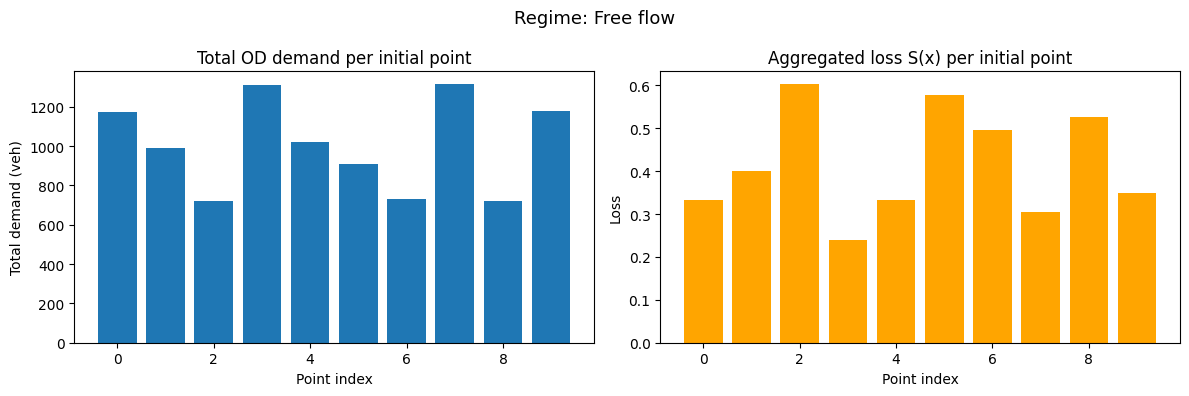


Free flow summary:
  Total demand range: 719 – 1315
  Loss range:         0.2406 – 0.6026


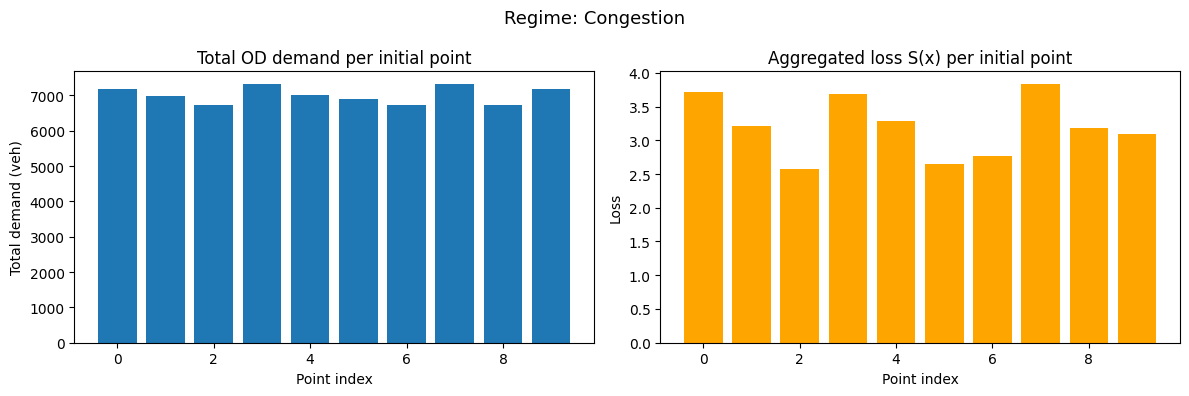


Congestion summary:
  Total demand range: 6716 – 7314
  Loss range:         2.5791 – 3.8299

Mean OD demands:
  Free flow:   [267.1 242.2 240.4 258.1]
  Congestion:  [1766.6 1741.6 1739.9 1757.6]


In [19]:
import matplotlib.pyplot as plt

CAPACITY = 5400.0

def plot_regime_flows(df, regime_name, edge_ids):
    e_cols = [f"e_{eid}" for eid in edge_ids]
    
    # recover simulated flows is not direct from errors, 
    # so just plot the loss distribution and OD demand distribution
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    fig.suptitle(f"Regime: {regime_name}", fontsize=13)

    # Plot 1 — total OD demand per point
    x_cols = [f"x_{k+1}" for k in range(dim_od)]
    total_demand = df[x_cols].sum(axis=1)
    axes[0].bar(range(len(df)), total_demand)
    axes[0].set_title("Total OD demand per initial point")
    axes[0].set_xlabel("Point index")
    axes[0].set_ylabel("Total demand (veh)")

    # Plot 2 — aggregated loss per point
    axes[1].bar(range(len(df)), df["loss"], color="orange")
    axes[1].set_title("Aggregated loss S(x) per initial point")
    axes[1].set_xlabel("Point index")
    axes[1].set_ylabel("Loss")

    plt.tight_layout()
    plt.show()

    # Summary table
    print(f"\n{regime_name} summary:")
    print(f"  Total demand range: {total_demand.min():.0f} – {total_demand.max():.0f}")
    print(f"  Loss range:         {df['loss'].min():.4f} – {df['loss'].max():.4f}")

plot_regime_flows(df_freeflow,   "Free flow",   edge_ids)
plot_regime_flows(df_congestion, "Congestion",  edge_ids)

# Side-by-side demand comparison
x_cols = [f"x_{k+1}" for k in range(dim_od)]
print("\nMean OD demands:")
print("  Free flow:  ", df_freeflow[x_cols].mean().values.round(1))
print("  Congestion: ", df_congestion[x_cols].mean().values.round(1))



In [20]:
x_cols = [f"x_{k+1}" for k in range(dim_od)]

print("FREE FLOW initial OD vectors:")
for i, row in df_freeflow.iterrows():
    od_vals = np.array(row[x_cols].tolist(), dtype=float).round(1)
    print(f"  Point {i+1}: {od_vals}  |  loss={row['loss']:.4f}")

print("\nCONGESTION initial OD vectors:")
for i, row in df_congestion.iterrows():
    od_vals = np.array(row[x_cols].tolist(), dtype=float).round(1)
    print(f"  Point {i+1}: {od_vals}  |  loss={row['loss']:.4f}")



FREE FLOW initial OD vectors:
  Point 1: [498.8  53.1 411.7 210.3]  |  loss=0.3331
  Point 2: [226.9 419.2  37.6 308.5]  |  loss=0.3998
  Point 3: [109.9 175.8 349.3  87.8]  |  loss=0.6026
  Point 4: [366.3 292.6 224.7 426.7]  |  loss=0.2406
  Point 5: [293.5 195.8  78.3 454.9]  |  loss=0.3328
  Point 6: [ 53.  343.7 452.8  60. ]  |  loss=0.5765
  Point 7: [185.4  65.2 140.7 342.2]  |  loss=0.4954
  Point 8: [410.7 462.5 265.6 176.3]  |  loss=0.3045
  Point 9: [384.9 148.3 159.3  26.2]  |  loss=0.5263
  Point 10: [141.9 265.4 284.3 488.4]  |  loss=0.3496

CONGESTION initial OD vectors:
  Point 1: [1998.8 1552.2 1911.5 1709.7]  |  loss=3.7179
  Point 2: [1726.4 1919.  1536.6 1808.1]  |  loss=3.2161
  Point 3: [1609.1 1675.1 1849.  1587. ]  |  loss=2.5791
  Point 4: [1866.  1792.1 1724.2 1926.6]  |  loss=3.6788
  Point 5: [1793.1 1695.2 1577.5 1954.8]  |  loss=3.2896
  Point 6: [1552.1 1843.4 1952.7 1559.1]  |  loss=2.6515
  Point 7: [1684.7 1564.4 1640.  1841.9]  |  loss=2.7656
  Point 

# checking the per edge mean and standard dev

In [30]:
import numpy as np
E = np.array(train_E_list)  # shape (N0, L)
max_mean = E.mean(axis=0).max()
min_mean = E.mean(axis=0).min()
print("per-edge mean:", E.mean(axis=0))
print("per-edge std: ", E.std(axis=0)) 

print((max_mean)/(min_mean))

per-edge mean: [1.576808   0.13202648 0.46134056 0.54431862 2.5263068  0.5380837 ]
per-edge std:  [1.78639733 0.16625033 0.7454068  0.49590066 2.82248932 0.43200431]
19.13484909733317


The ratio is 19x (edge 4 mean=2.53 vs edge 1 mean=0.13). That's above the threshold — per-task standardization is warranted here.

The GP's joint standardization is being dominated by edges 0 and 4 (the high-variance ones), effectively compressing edges 1, 3, and 5 into a narrow band. The lengthscale and outputscale learned by MLL will be a compromise that doesn't serve any edge well.

In [31]:
print (f"errors aggregated {S_list}") # USED FOR BEST S INITIAL  
print (f"training od {train_X_list}")

errors aggregated [2.194447539262619, 0.7624201537750904, 0.0948045574032082, 1.495016295540438, 0.7560193817922232, 0.2431851231208532, 0.0892360763416477, 2.169921887545142, 1.2150989437305784, 0.6113236562526245]
training od [array([1995.0291943 ,  209.6284174 , 1646.1347295 ,  839.44489431]), array([ 905.94906542, 1676.29651904,  147.46766934, 1232.72368908]), array([ 437.14938757,  701.09495258, 1396.15559268,  348.7577768 ]), array([1464.2524972 , 1169.00970572,  897.1642783 , 1706.55827516]), array([1172.87885344,  781.21352413,  310.67503536, 1819.32773274]), array([ 209.22147655, 1374.04689205, 1810.88264138,  237.16270319]), array([ 739.54443675,  258.35545552,  560.69944906, 1367.81321883]), array([1642.19337708, 1849.9723168 , 1061.07939345,  703.05895641]), array([1538.87189376,  591.19217685,  635.09258038,  102.02450824]), array([ 565.50809205, 1060.32326955, 1136.02752399, 1953.71856874])]


# bounds common for all methods 

In [9]:
seed = 42
set_seed(seed)

######### BUILD INITIAL DATA (same source as Scalar GP / Ind-GP: train_X_list, train_E_list)
train_X_icm_init = torch.tensor(np.array(train_X_list), dtype=dtype, device=device)  # [N0, d]
train_Y_raw_init = torch.tensor(np.array(train_E_list), dtype=dtype, device=device)   # [N0, L]

N0, d = train_X_icm_init.shape
L = train_Y_raw_init.shape[1]

# Bounds from config — same as Scalar GP / Ind-GP ([1, 2000] by default)
od_bound_start = config.get("od_bound_start", 1)
od_bound_end   = config.get("od_bound_end", 2000)
bounds = torch.stack([
    torch.full((d,), od_bound_start, dtype=dtype, device=device),
    torch.full((d,), od_bound_end, dtype=dtype, device=device),
])

bounds_norm = torch.stack([
    torch.zeros(d, dtype=dtype, device=device),
    torch.ones(d, dtype=dtype, device=device),
])

# Uniform weights for scalarization (same as other methods)
weights_uniform = torch.ones(L, dtype=dtype, device=device)
weights_uniform = weights_uniform / weights_uniform.sum()

print(weights_uniform)

tensor([0.1667, 0.1667, 0.1667, 0.1667, 0.1667, 0.1667], dtype=torch.float64)


# ICM CLEAN

# full icm rank 1

In [33]:
import time
import json
import numpy as np
import pandas as pd
from pathlib import Path
import xml.etree.ElementTree as _ET

from MOGP.helpers_MOGP import fit_gpytorch_mll_with_adam_fallback

dtype = torch.double
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

N_RESTARTS = 5
N_BO_ITERS = 200
BO_FOLDER  = "ICM_squared"


def _load_icm_iters(sim_base, n_bo_iters, train_X_init, train_Y_init,
                    best_S_init, edge_ids, weights_np, device, dtype):
    """Load already-completed BO iterations from disk, resuming where we left off."""
    train_X = train_X_init.clone()
    train_Y = train_Y_init.clone()
    best_S  = best_S_init
    S_hist_best = [best_S_init]
    S_hist_obs  = [float("nan")]
    start_iter  = 0

    for _it in range(n_bo_iters):
        od_xml      = sim_base / f"iter_{_it}" / "od.xml"
        compare_csv = sim_base / f"iter_{_it}" / "link_measure_compare.csv"
        if not od_xml.exists() or not compare_csv.exists():
            break

        tree   = _ET.parse(str(od_xml))
        rows   = [el.attrib for el in tree.getroot().iter("tazRelation")]
        counts = pd.DataFrame(rows)["count"].astype(float).values
        _x     = torch.tensor(counts, device=device, dtype=dtype).view(1, -1)

        _df = pd.read_csv(str(compare_csv)).set_index("edge_id")
        per_edge_errors = []
        for eid in edge_ids:
            if eid in _df.index:
                gt_val  = float(_df.loc[eid, "interval_nVehContrib_gt"])
                sim_val = float(_df.loc[eid, "interval_nVehContrib_sim"])
                if gt_val > 0:
                    per_edge_errors.append(((sim_val - gt_val) / gt_val) ** 2)
                else:
                    per_edge_errors.append(np.nan)
            else:
                per_edge_errors.append(np.nan)

        _y    = torch.tensor(per_edge_errors, device=device, dtype=dtype).view(1, -1)
        _loss = float((np.asarray(per_edge_errors) * weights_np).sum())
        if np.isnan(_loss):
            _loss = float("inf")

        train_X = torch.cat([train_X, _x], dim=0)
        train_Y = torch.cat([train_Y, _y], dim=0)
        if _loss < best_S:
            best_S = _loss
        S_hist_best.append(best_S)
        S_hist_obs.append(_loss)
        start_iter = _it + 1

    return train_X, train_Y, best_S, S_hist_best, S_hist_obs, start_iter


def _log_icm_hyperparameters(icm_model, iteration, rank, hp_log_path):
    """Save ICM hyperparameters for one iteration to CSV (one row per task)."""
    ls         = icm_model.covar_module.data_covar_module.lengthscale.detach().cpu().numpy().flatten()
    ls_mean    = float(ls.mean())
    ls_min     = float(ls.min())
    ls_max     = float(ls.max())
    ls_per_dim = {f"lengthscale_dim_{i}": float(ls[i]) for i in range(len(ls))}

    task_mod = icm_model.covar_module.task_covar_module
    B   = task_mod.covar_factor.detach().cpu().numpy()
    var = task_mod.var.detach().cpu().numpy().flatten()
    noise = float(icm_model.likelihood.noise.detach().cpu().item())

    rows = []
    for l in range(len(var)):
        row = {
            "iteration":        iteration,
            "task":             l,
            "lengthscale_mean": ls_mean,
            "lengthscale_min":  ls_min,
            "lengthscale_max":  ls_max,
            "task_var":         float(var[l]),
            "noise":            noise,
            **ls_per_dim,
        }
        for r_idx in range(rank):
            row[f"B_{l}_{r_idx}"] = float(B[l, r_idx])
        rows.append(row)

    df = pd.DataFrame(rows)
    write_header = not hp_log_path.exists()
    df.to_csv(hp_log_path, mode="a", header=write_header, index=False)


def _pad(lst, n, fill=np.nan):
    return lst + [fill] * (n - len(lst))


for rank in [1, 2, 3]:
    print(f"\n{'='*60}")
    print(f"RUNNING ICM RANK {rank}")
    print(f"{'='*60}")

    run_label = f"rank{rank}"
    config["simulation_run_path"] = f"output/{config.get('network_name', 'quickstart')}_icm_{run_label}_squared_2"
    Path(config["simulation_run_path"]).mkdir(parents=True, exist_ok=True)

    results_dir = Path(config["simulation_run_path"]) / BO_FOLDER / "results"
    results_dir.mkdir(parents=True, exist_ok=True)

    skip_if_saved = config.get("SKIP_RESTART_IF_SAVED", True)
    n_init = train_X_icm_init.shape[0]

    icm_histories_best_raw     = []
    icm_histories_observed_raw = []
    icm_seeds_used             = []

    for r in range(N_RESTARTS):
        restart_seed     = 42 + r * 1000
        restart_dir      = results_dir / f"restart_{r+1}_seed-{restart_seed}"
        convergence_file = restart_dir / "convergence.csv"
        hp_log_path      = restart_dir / "hyperparameters_per_iteration.csv"

        # --- skip fully completed restarts ---
        if skip_if_saved and convergence_file.exists():
            df_prev   = pd.read_csv(convergence_file)
            best_hist = df_prev["best_S_raw"].tolist() if "best_S_raw" in df_prev.columns else df_prev["best_S_model"].tolist()
            obs_hist  = df_prev["observed_S_raw"].tolist() if "observed_S_raw" in df_prev.columns else [np.nan] * len(best_hist)

            while best_hist and pd.isna(best_hist[-1]): best_hist.pop()
            while obs_hist  and pd.isna(obs_hist[-1]):  obs_hist.pop()

            # only skip if fully done
            if len(best_hist) == 1 + N_BO_ITERS:
                icm_histories_best_raw.append(best_hist)
                icm_histories_observed_raw.append(obs_hist)
                icm_seeds_used.append(restart_seed)
                print(f"\n### ICM rank={rank} RESTART {r+1}/{N_RESTARTS} (seed={restart_seed}) — SKIPPED ###")
                print(f"  Loaded {len(best_hist)} rows, best S={best_hist[-1]:.6f}")
                continue

        print(f"\n### ICM rank={rank} RESTART {r+1}/{N_RESTARTS} (seed={restart_seed}) ###")
        set_seed(restart_seed)
        icm_seeds_used.append(restart_seed)

        restart_dir.mkdir(parents=True, exist_ok=True)

        # --- resume partially completed restart ---
        best_S_init_val = float((train_Y_raw_init * weights_uniform).sum(dim=1).min().item())
        sim_base        = Path(base_path) / config["simulation_run_path"] / f"icm_bo_restart_{r}"

        train_X_icm, train_Y_icm_raw, best_S_raw, S_history_best_raw, S_history_observed_raw, start_iter = _load_icm_iters(
            sim_base, N_BO_ITERS,
            train_X_icm_init, train_Y_raw_init,
            best_S_init_val, edge_ids, weights_np,
            device, dtype,
        )

        # clear partial hp log if starting from scratch
        if start_iter == 0 and hp_log_path.exists():
            hp_log_path.unlink()

        if start_iter > 0:
            print(f"[RESUME] Loaded {start_iter} iters → resuming from iter {start_iter+1}/{N_BO_ITERS}, best S={best_S_raw:.6f}")
        else:
            print(f"[INIT] N={n_init}, best S={best_S_raw:.6f}")

        acq_values_list = [float("nan")] * (1 + start_iter)
        wall_times_list = [0.0]         * (1 + start_iter)

        for it in range(start_iter, N_BO_ITERS):
            iter_t0 = time.time()
            print(f"\n--- ICM rank={rank} BO ITER {it+1}/{N_BO_ITERS} ---")

            y_mean = train_Y_icm_raw.mean(dim=0, keepdim=True)
            y_std  = train_Y_icm_raw.std(dim=0,  keepdim=True).clamp_min(1e-6)
            train_Y_icm = (train_Y_icm_raw - y_mean) / y_std

            sigma_l       = y_std.squeeze(0)
            weights_for_Z = (weights_uniform * sigma_l).to(device=device, dtype=dtype)
            best_f_for_ei = (train_Y_icm * weights_for_Z).sum(dim=1).min().item()
            train_X_norm  = normalize(train_X_icm, bounds=bounds)

            icm_model, mll = initialize_icm_gp(train_X_norm, train_Y_icm, rank=rank)
            icm_model = icm_model.to(device=device, dtype=dtype)
            icm_model.likelihood = icm_model.likelihood.to(device=device, dtype=dtype)
            mll = mll.to(device=device, dtype=dtype)

            agg_model = LinearAggregationICM(icm_model, weights_for_Z).to(device=device, dtype=dtype)

            icm_model.train()
            mll.train()
            fit_method = fit_gpytorch_mll_with_adam_fallback(mll, verbose=False)
            print(f"[FIT] method={fit_method}")

            icm_model.eval()
            agg_model.eval()

            _log_icm_hyperparameters(icm_model, it, rank, hp_log_path)

            EI = ExpectedImprovement(model=agg_model, best_f=best_f_for_ei, maximize=False)
            x_next_norm, acq_val = optimize_acqf(
                EI,
                bounds=bounds_norm,
                q=1,
                num_restarts=config.get("BO_num_restarts", 10),
                raw_samples=config.get("BO_sample_shape", 128),
            )
            x_next_norm = x_next_norm.detach()
            acq_values_list.append(acq_val.item())

            x_next_real = unnormalize(x_next_norm, bounds).view(-1).cpu().numpy()
            x_next_real = np.clip(x_next_real, od_bound_start, od_bound_end)
            print(f"[ACQ] EI={acq_val.item():.6f}, x_next sum={x_next_real.sum():.2f}")

            sim_dir_abs = sim_base / f"iter_{it}"
            sim_dir_abs.mkdir(parents=True, exist_ok=True)

            sim_dir_rel         = str(sim_dir_abs.relative_to(base_path))
            new_od_xml_relative = f"{sim_dir_rel}/od.xml"
            prefix_output_rel   = f"{sim_dir_rel}/sim"

            base_od = gt_od_df.copy()
            base_od["count"] = x_next_real
            base_od = base_od.rename(columns={"fromTaz": "from", "toTaz": "to"})

            create_taz_xml(new_od_xml_relative, base_od, config["od_duration_sec"], str(base_path))

            simulate_od(
                new_od_xml_relative, prefix_output_rel, str(base_path),
                config["net_xml"], config["taz2edge_xml"], config["additional_xml"],
                routes_df, config["sim_end_time"], config["TRIPS2ODS_OUT_STR"],
                seed=restart_seed + it,
            )

            sim_edge_out = str(Path(base_path) / f"{prefix_output_rel}_{config['EDGE_OUT_STR']}")
            curr_loop_stats, _, _ = parse_loop_data_xml_to_pandas(
                str(base_path), sim_edge_out, prefix_output_rel, str(config["SUMO_PATH"]),
            )
            curr_loop_stats_grouped = group_edge_dataframe(curr_loop_stats)

            e_next = compute_squared_metric_per_edge(
                df_true=gt_edge_grouped,
                df_simulated=curr_loop_stats_grouped,
                edge_ids=edge_ids,
            )

            # save link_measure_compare.csv so resume can reload this iter
            merged = pd.merge(
                gt_edge_grouped[["edge_id", "interval_nVehContrib"]],
                curr_loop_stats_grouped[["edge_id", "interval_nVehContrib"]],
                on="edge_id", suffixes=("_gt", "_sim"),
            )
            merged.to_csv(sim_dir_abs / "link_measure_compare.csv", index=False)

            e_next_tensor = torch.tensor(e_next, device=device, dtype=dtype)
            S_next_raw    = (e_next_tensor * weights_uniform).sum().item()
            S_history_observed_raw.append(S_next_raw)
            print(f"[SIM] S_next_raw={S_next_raw:.6f}")

            if S_next_raw < best_S_raw:
                best_S_raw = S_next_raw
                print(f"[UPDATE] New BEST S={best_S_raw:.6f}")
            else:
                print(f"[NO IMPROVEMENT] Best S remains {best_S_raw:.6f}")

            S_history_best_raw.append(best_S_raw)

            train_X_icm     = torch.cat([train_X_icm,     torch.tensor(x_next_real, device=device, dtype=dtype).view(1, -1)], dim=0)
            train_Y_icm_raw = torch.cat([train_Y_icm_raw, e_next_tensor.view(1, -1)], dim=0)

            wall_times_list.append(time.time() - iter_t0)
            print(f"[DATA] N={train_X_icm.shape[0]}, time={wall_times_list[-1]:.2f}s")

        icm_histories_best_raw.append(S_history_best_raw)
        icm_histories_observed_raw.append(S_history_observed_raw)
        print(f"\n[RESTART COMPLETE] rank={rank}, best S={best_S_raw:.6f}")

        assert len(S_history_best_raw) == 1 + N_BO_ITERS

        pd.DataFrame({
            "evaluation":     range(len(S_history_best_raw)),
            "best_S_raw":     S_history_best_raw,
            "observed_S_raw": S_history_observed_raw,
            "acq_value":      acq_values_list,
            "wall_time_sec":  wall_times_list,
        }).to_csv(restart_dir / "convergence.csv", index=False)
        print(f"✓ Convergence saved: {restart_dir / 'convergence.csv'}")
        print(f"✓ Hyperparameters saved: {hp_log_path}")

    # Aggregate across restarts
    max_len = max(len(h) for h in icm_histories_best_raw)
    padded  = np.full((len(icm_histories_best_raw), max_len), np.nan)
    for i, h in enumerate(icm_histories_best_raw):
        padded[i, :len(h)] = h

    mean_curve         = np.nanmean(padded, axis=0)
    std_curve          = np.nanstd(padded,  axis=0)
    best_S_per_restart = [h[-1] for h in icm_histories_best_raw]
    overall_best       = min(best_S_per_restart)

    print(f"\nICM rank={rank} COMPLETE")
    print(f"Best S per restart: {[f'{s:.6f}' for s in best_S_per_restart]}")
    print(f"Mean: {np.mean(best_S_per_restart):.6f} ± {np.std(best_S_per_restart):.6f}")
    print(f"Overall best: {overall_best:.6f}")

    pd.DataFrame({
        "evaluation":  range(len(mean_curve)),
        "best_S_mean": mean_curve,
        "best_S_std":  std_curve,
    }).to_csv(results_dir / "convergence_mean_std.csv", index=False)

    df_histories = pd.DataFrame({
        f"restart_{r+1}": _pad(icm_histories_best_raw[r], max_len)
        for r in range(len(icm_histories_best_raw))
    })
    df_histories["mean"] = mean_curve
    df_histories.index.name = "evaluation"
    df_histories.to_csv(results_dir / "all_restarts_convergence.csv")

    with open(results_dir / "summary.json", "w") as f:
        json.dump({
            "best_S_per_restart": best_S_per_restart,
            "best_S_mean":        float(np.mean(best_S_per_restart)),
            "best_S_std":         float(np.std(best_S_per_restart)),
            "overall_best_S":     float(overall_best),
            "n_restarts":         N_RESTARTS,
            "n_bo_iters":         N_BO_ITERS,
            "n_initial":          n_init,
            "model":              "icm",
            "rank":               rank,
            "metric":             "squared",
            "network_name":       config.get("network_name", "quickstart"),
            "od_bound_start":     od_bound_start,
            "od_bound_end":       od_bound_end,
        }, f, indent=2)

    print(f"\n✓ Saved rank={rank}: {results_dir}")
    print("  - restart_X_seed-Y/convergence.csv")
    print("  - restart_X_seed-Y/hyperparameters_per_iteration.csv")
    print("  - convergence_mean_std.csv, summary.json, all_restarts_convergence.csv")






RUNNING ICM RANK 1

### ICM rank=1 RESTART 1/5 (seed=42) — SKIPPED ###
  Loaded 201 rows, best S=0.000011

### ICM rank=1 RESTART 2/5 (seed=1042) — SKIPPED ###
  Loaded 201 rows, best S=0.000001

### ICM rank=1 RESTART 3/5 (seed=2042) — SKIPPED ###
  Loaded 201 rows, best S=0.000009

### ICM rank=1 RESTART 4/5 (seed=3042) — SKIPPED ###
  Loaded 201 rows, best S=0.000000

### ICM rank=1 RESTART 5/5 (seed=4042) — SKIPPED ###
  Loaded 201 rows, best S=0.000022

ICM rank=1 COMPLETE
Best S per restart: ['0.000011', '0.000001', '0.000009', '0.000000', '0.000022']
Mean: 0.000009 ± 0.000008
Overall best: 0.000000

✓ Saved rank=1: output/quickstart_icm_rank1_squared_2/ICM_squared/results
  - restart_X_seed-Y/convergence.csv
  - restart_X_seed-Y/hyperparameters_per_iteration.csv
  - convergence_mean_std.csv, summary.json, all_restarts_convergence.csv

RUNNING ICM RANK 2

### ICM rank=2 RESTART 1/5 (seed=42) — SKIPPED ###
  Loaded 201 rows, best S=0.000131

### ICM rank=2 RESTART 2/5 (seed=1042)

/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/env/lib/python3.12/site-packages/botorch/acquisition/analytic.py:340: NumericsWarning: ExpectedImprovement has known numerical issues that lead to suboptimal optimization performance. It is strongly recommended to simply replace

	 ExpectedImprovement 	 --> 	 LogExpectedImprovement 

instead, which fixes the issues and has the same API. See https://arxiv.org/abs/2310.20708 for details.
  legacy_ei_numerics_warning(legacy_name=type(self).__name__)


[ACQ] EI=0.000000, x_next sum=3022.69
Created /Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/output/quickstart_icm_rank2_squared_2/icm_bo_restart_3/iter_82/od.xml
od2trips --spread.uniform --taz-files /Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/network/quickstart/taz.xml --tazrelation-files output/quickstart_icm_rank2_squared_2/icm_bo_restart_3/iter_82/od.xml --seed 3124 -o /Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/output/quickstart_icm_rank2_squared_2/icm_bo_restart_3/iter_82/sim_trips_beforeRteUpdates.xml
Running SUMO: sumo --output-prefix output/quickstart_icm_rank2_squared_2/icm_bo_restart_3/iter_82/sim_ --ignore-route-errors=true --net-file=/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/network/quickstart/net.xml --routes=/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/output/quickstart_icm_rank2_squared_2/icm_bo_restart_3/iter_82/sim_trips.xml -b 0 -e 57600 --additional-files /Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/network/quickstart/addition

/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/env/lib/python3.12/site-packages/botorch/acquisition/analytic.py:340: NumericsWarning: ExpectedImprovement has known numerical issues that lead to suboptimal optimization performance. It is strongly recommended to simply replace

	 ExpectedImprovement 	 --> 	 LogExpectedImprovement 

instead, which fixes the issues and has the same API. See https://arxiv.org/abs/2310.20708 for details.
  legacy_ei_numerics_warning(legacy_name=type(self).__name__)


[ACQ] EI=0.000000, x_next sum=2464.89
Created /Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/output/quickstart_icm_rank2_squared_2/icm_bo_restart_3/iter_83/od.xml
od2trips --spread.uniform --taz-files /Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/network/quickstart/taz.xml --tazrelation-files output/quickstart_icm_rank2_squared_2/icm_bo_restart_3/iter_83/od.xml --seed 3125 -o /Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/output/quickstart_icm_rank2_squared_2/icm_bo_restart_3/iter_83/sim_trips_beforeRteUpdates.xml
Running SUMO: sumo --output-prefix output/quickstart_icm_rank2_squared_2/icm_bo_restart_3/iter_83/sim_ --ignore-route-errors=true --net-file=/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/network/quickstart/net.xml --routes=/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/output/quickstart_icm_rank2_squared_2/icm_bo_restart_3/iter_83/sim_trips.xml -b 0 -e 57600 --additional-files /Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/network/quickstart/addition

...

/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/env/lib/python3.12/site-packages/botorch/acquisition/analytic.py:340: NumericsWarning: ExpectedImprovement has known numerical issues that lead to suboptimal optimization performance. It is strongly recommended to simply replace

	 ExpectedImprovement 	 --> 	 LogExpectedImprovement 

instead, which fixes the issues and has the same API. See https://arxiv.org/abs/2310.20708 for details.
  legacy_ei_numerics_warning(legacy_name=type(self).__name__)


[ACQ] EI=0.000000, x_next sum=2873.66
Created /Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/output/quickstart_icm_rank3_squared_2/icm_bo_restart_1/iter_38/od.xml
od2trips --spread.uniform --taz-files /Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/network/quickstart/taz.xml --tazrelation-files output/quickstart_icm_rank3_squared_2/icm_bo_restart_1/iter_38/od.xml --seed 1080 -o /Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/output/quickstart_icm_rank3_squared_2/icm_bo_restart_1/iter_38/sim_trips_beforeRteUpdates.xml
Running SUMO: sumo --output-prefix output/quickstart_icm_rank3_squared_2/icm_bo_restart_1/iter_38/sim_ --ignore-route-errors=true --net-file=/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/network/quickstart/net.xml --routes=/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/output/quickstart_icm_rank3_squared_2/icm_bo_restart_1/iter_38/sim_trips.xml -b 0 -e 57600 --additional-files /Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/network/quickstart/addition

/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/env/lib/python3.12/site-packages/botorch/acquisition/analytic.py:340: NumericsWarning: ExpectedImprovement has known numerical issues that lead to suboptimal optimization performance. It is strongly recommended to simply replace

	 ExpectedImprovement 	 --> 	 LogExpectedImprovement 

instead, which fixes the issues and has the same API. See https://arxiv.org/abs/2310.20708 for details.
  legacy_ei_numerics_warning(legacy_name=type(self).__name__)


[ACQ] EI=0.000932, x_next sum=2800.27
Created /Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/output/quickstart_icm_rank3_squared_2/icm_bo_restart_1/iter_39/od.xml
od2trips --spread.uniform --taz-files /Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/network/quickstart/taz.xml --tazrelation-files output/quickstart_icm_rank3_squared_2/icm_bo_restart_1/iter_39/od.xml --seed 1081 -o /Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/output/quickstart_icm_rank3_squared_2/icm_bo_restart_1/iter_39/sim_trips_beforeRteUpdates.xml
Running SUMO: sumo --output-prefix output/quickstart_icm_rank3_squared_2/icm_bo_restart_1/iter_39/sim_ --ignore-route-errors=true --net-file=/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/network/quickstart/net.xml --routes=/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/output/quickstart_icm_rank3_squared_2/icm_bo_restart_1/iter_39/sim_trips.xml -b 0 -e 57600 --additional-files /Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/network/quickstart/addition

KeyboardInterrupt: 


=== ICM rank=1 — B matrix (L×rank = (6, 1)) ===
       r0
0  1.2566
1 -3.3132
2  1.5065
3 -2.8260
4  2.0981
5 -6.9190

K_task ((6, 6)):
         0        1        2        3        4        5
0 104.4434  -4.1635   1.8932  -3.5512   2.6365  -8.6946
1  -4.1635 152.1144  -4.9915   9.3631  -6.9514  22.9241
2   1.8932  -4.9915 172.9358  -4.2575   3.1609 -10.4238
3  -3.5512   9.3631  -4.2575 136.5539  -5.9292  19.5529
4   2.6365  -6.9514   3.1609  -5.9292 113.9717 -14.5167
5  -8.6946  22.9241 -10.4238  19.5529 -14.5167 125.1722

Correlation matrix:
       L12    L14    L18    L10    L15    L16
L12  1.000 -0.033  0.014 -0.030  0.024 -0.076
L14 -0.033  1.000 -0.031  0.065 -0.053  0.166
L18  0.014 -0.031  1.000 -0.028  0.023 -0.071
L10 -0.030  0.065 -0.028  1.000 -0.048  0.150
L15  0.024 -0.053  0.023 -0.048  1.000 -0.122
L16 -0.076  0.166 -0.071  0.150 -0.122  1.000


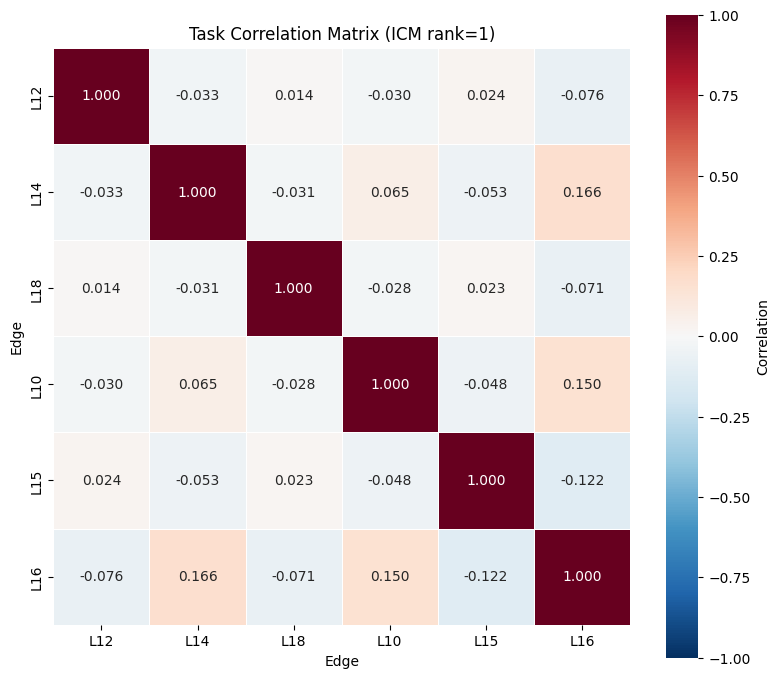


=== ICM rank=2 — B matrix (L×rank = (6, 2)) ===
       r0      r1
0  1.5837  1.2115
1 -0.3444 -5.5602
2  4.1249 -2.8417
3 -2.7790 -0.4404
4  2.3499  0.5637
5 -5.0516 -3.8368

K_task ((6, 6)):
         0        1        2        3        4        5
0 101.9385  -7.2819   3.0898  -4.9346   4.4044 -12.6486
1  -7.2819 149.6628  14.3798   3.4057  -3.9436  23.0730
2   3.0898  14.3798 164.2452 -10.2117   8.0911  -9.9343
3  -4.9346   3.4057 -10.2117 116.0344  -6.7785  15.7279
4   4.4044  -3.9436   8.0911  -6.7785 112.2639 -14.0333
5 -12.6486  23.0730  -9.9343  15.7279 -14.0333 146.4875

Correlation matrix:
       L12    L14    L18    L10    L15    L16
L12  1.000 -0.059  0.024 -0.045  0.041 -0.104
L14 -0.059  1.000  0.092  0.026 -0.030  0.156
L18  0.024  0.092  1.000 -0.074  0.060 -0.064
L10 -0.045  0.026 -0.074  1.000 -0.059  0.121
L15  0.041 -0.030  0.060 -0.059  1.000 -0.109
L16 -0.104  0.156 -0.064  0.121 -0.109  1.000


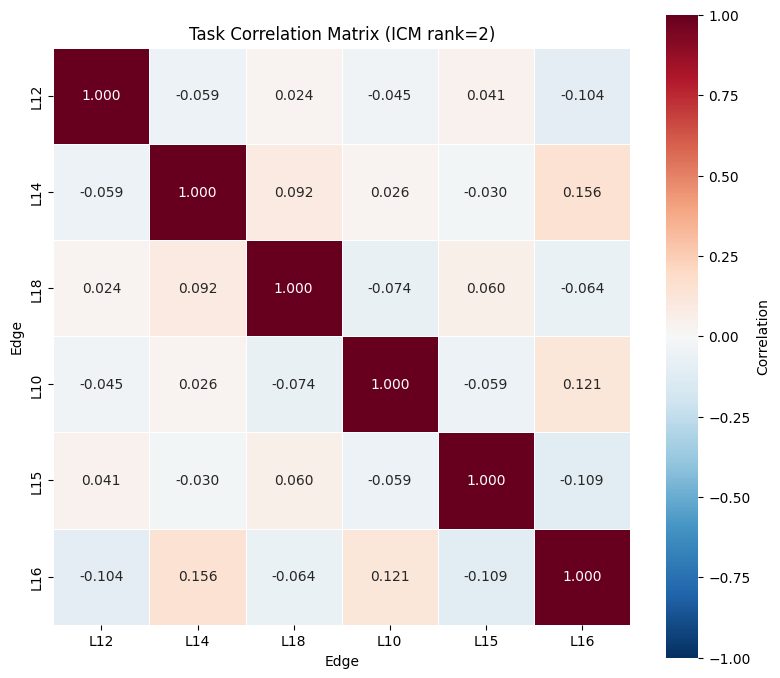


=== ICM rank=3 — B matrix (L×rank = (6, 3)) ===
       r0      r1      r2
0 -1.2054 -5.6042 -3.1199
1 -0.5971  6.7691 -3.2096
2  7.9577  1.5029 -5.7622
3 -5.4826  0.2984 -3.3694
4  2.6810 -3.8273 -2.7994
5 -7.3670  6.9727 -4.0384

K_task ((6, 6)):
         0        1        2        3        4        5
0  97.1331 -27.2023  -0.0370  15.4479  26.9509 -17.5973
1 -27.2023 168.8945  23.9156  16.1083 -18.5235  64.5598
2  -0.0370  23.9156 152.6993 -23.7654  31.7134 -24.8750
3  15.4479  16.1083 -23.7654 128.7951  -6.4090  56.0779
4  26.9509 -18.5235  31.7134  -6.4090 109.4911 -35.1326
5 -17.5973  64.5598 -24.8750  56.0779 -35.1326 220.5502

Correlation matrix:
       L12    L14    L18    L10    L15    L16
L12  1.000 -0.212 -0.000  0.138  0.261 -0.120
L14 -0.212  1.000  0.149  0.109 -0.136  0.335
L18 -0.000  0.149  1.000 -0.169  0.245 -0.136
L10  0.138  0.109 -0.169  1.000 -0.054  0.333
L15  0.261 -0.136  0.245 -0.054  1.000 -0.226
L16 -0.120  0.335 -0.136  0.333 -0.226  1.000


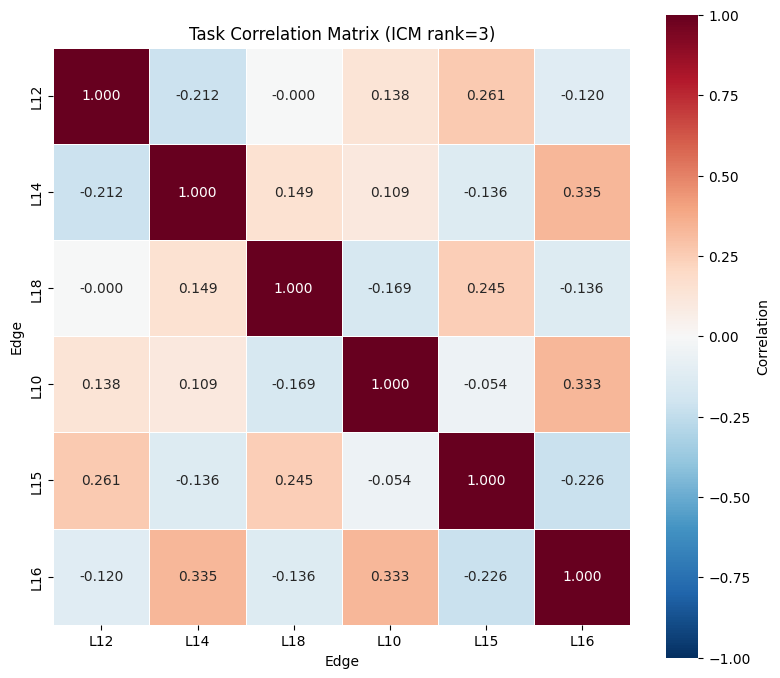

In [25]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

edge_labels = list(edge_ids)

for rank in [1, 2, 3]:
    results_dir = Path(f"output/quickstart_icm_rank{rank}_squared_2/ICM_squared/results")

    dfs = []
    for r in range(5):
        seed = 42 + r * 1000
        p = results_dir / f"restart_{r+1}_seed-{seed}" / "hyperparameters_per_iteration.csv"
        if p.exists():
            df = pd.read_csv(p)
            df["restart"] = r + 1
            dfs.append(df)

    all_df = pd.concat(dfs, ignore_index=True)
    final  = all_df[all_df["iteration"] == all_df["iteration"].max()]
    L      = final["task"].nunique()

    B_mat   = np.zeros((L, rank))
    var_mat = np.zeros(L)
    for task_id in range(L):
        rows = final[final["task"] == task_id]
        for r_idx in range(rank):
            col = f"B_{task_id}_{r_idx}"
            if col in rows.columns:
                B_mat[task_id, r_idx] = rows[col].mean()
        var_mat[task_id] = rows["task_var"].mean()

    K_task = B_mat @ B_mat.T + np.diag(var_mat)

    # Normalize to correlation matrix
    D = np.sqrt(np.diag(K_task))
    corr = K_task / np.outer(D, D)
    corr_df = pd.DataFrame(corr, index=edge_labels, columns=edge_labels)

    print(f"\n=== ICM rank={rank} — B matrix (L×rank = {B_mat.shape}) ===")
    print(pd.DataFrame(B_mat, columns=[f"r{i}" for i in range(rank)]).to_string(float_format=lambda x: f"{x:.4f}"))
    print(f"\nK_task ({K_task.shape}):")
    print(pd.DataFrame(K_task).to_string(float_format=lambda x: f"{x:.4f}"))
    print(f"\nCorrelation matrix:")
    print(corr_df.to_string(float_format=lambda x: f"{x:.3f}"))

    fig, ax = plt.subplots(figsize=(8, 7))
    sns.heatmap(
        corr_df,
        annot=True, fmt=".3f",
        cmap="RdBu_r", center=0, vmin=-1, vmax=1,
        square=True, linewidths=0.5,
        cbar_kws={"label": "Correlation"},
        ax=ax,
    )
    ax.set_title(f"Task Correlation Matrix (ICM rank={rank})")
    ax.set_xlabel("Edge")
    ax.set_ylabel("Edge")
    plt.tight_layout()
    plt.savefig(results_dir / f"task_correlation_rank{rank}.pdf", bbox_inches="tight")
    plt.show()




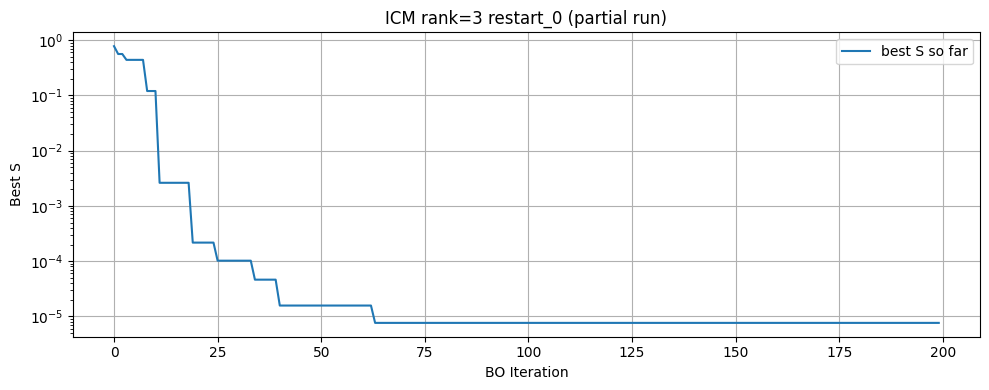

Completed iters: 200, best S: 0.000008


In [27]:
import xml.etree.ElementTree as _ET
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

sim_base = Path("output/quickstart_icm_rank3_squared_2/icm_bo_restart_0")

S_hist = []
for it in range(200):
    od_xml      = sim_base / f"iter_{it}" / "od.xml"
    compare_csv = sim_base / f"iter_{it}" / "link_measure_compare.csv"
    if not od_xml.exists() or not compare_csv.exists():
        print(f"Stopped at iter {it}")
        break

    _df = pd.read_csv(str(compare_csv)).set_index("edge_id")
    per_edge_errors = []
    for eid in edge_ids:
        if eid in _df.index:
            gt_val  = float(_df.loc[eid, "interval_nVehContrib_gt"])
            sim_val = float(_df.loc[eid, "interval_nVehContrib_sim"])
            if gt_val > 0:
                per_edge_errors.append(((sim_val - gt_val) / gt_val) ** 2)
            else:
                per_edge_errors.append(np.nan)
        else:
            per_edge_errors.append(np.nan)

    S = float((np.asarray(per_edge_errors) * weights_np).sum())
    S_hist.append(S)

best_S = np.minimum.accumulate(S_hist)

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(best_S, label="best S so far")
ax.set_xlabel("BO Iteration")
ax.set_ylabel("Best S")
ax.set_yscale("log")
ax.set_title("ICM rank=3 restart_0 (partial run)")
ax.grid(True)
ax.legend()
plt.tight_layout()
plt.show()
print(f"Completed iters: {len(S_hist)}, best S: {best_S[-1]:.6f}")


Skip ICM (rank 3): not found at /Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/output/quickstart_icm_rank3_squared_2/ICM_squared/results/all_restarts_convergence.csv


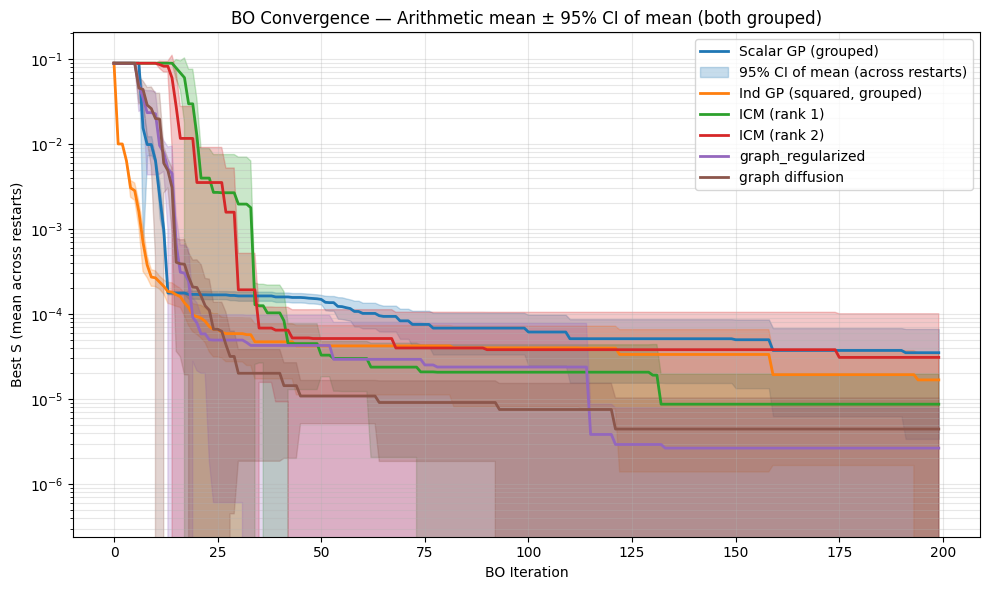

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from scipy import stats
from pathlib import Path
import pandas as pd

base_path = Path("/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn")
sim_path = base_path / "output" / "quickstart_bo_vanilla_matern-2p5"

n_show = 200

methods = {
    "Scalar GP (grouped)": sim_path / "ScalarGP" / "noise_1e-4_1" / "NEW" / "results" / "all_restarts_convergence.csv",
    "Ind GP (squared, grouped)": sim_path / "indgp_bo_squared_grouped" / "noise_1e-4_1" / "NEW" / "results" / "all_restarts_convergence.csv",
    "ICM (rank 1)": base_path/ "output"/ "quickstart_icm_rank1_squared_2" / "ICM_squared"/"results"/"all_restarts_convergence.csv",
    "ICM (rank 2)": base_path/ "output"/ "quickstart_icm_rank2_squared_2" / "ICM_squared"/"results"/"all_restarts_convergence.csv",
    "ICM (rank 3)": base_path/ "output"/ "quickstart_icm_rank3_squared_2" / "ICM_squared"/"results"/"all_restarts_convergence.csv",
    "graph_regularized" : base_path / "output" / "quickstart_graph_diffusion_squared_NEW" /"graph_bo_regularized_laplacian_NEW" /"results" / "all_restarts_convergence.csv",
    "graph diffusion" : base_path / "output" / "quickstart_graph_diffusion_squared_NEW" /"graph_bo_diffusion_shared_node" /"results" / "all_restarts_convergence.csv", 
}

fig, ax = plt.subplots(figsize=(10, 6))
first_method = True  

for label, path in methods.items():
    if not path.exists():
        print(f"Skip {label}: not found at {path}")
        continue

    df = pd.read_csv(path).head(n_show)

    restart_cols = [c for c in df.columns if c.startswith("restart_")]
    if restart_cols:
        S = df[restart_cols].to_numpy(dtype=float)
    elif "mean" in df.columns:
        S = df[["mean"]].to_numpy(dtype=float)
    elif "best_S" in df.columns:
        S = df[["best_S"]].to_numpy(dtype=float)
    else:
        print(f"Skip {label}: no restart_*, mean, or best_S column")
        continue

    # Arithmetic mean and 95% CI of mean 
    n_restarts = S.shape[1]
    mean_curve = np.nanmean(S, axis=1)
    std_curve = np.nanstd(S, axis=1, ddof=1) if n_restarts > 1 else np.zeros(len(mean_curve))
    t_critical = stats.t.ppf(0.975, df=n_restarts - 1) if n_restarts > 1 else 0
    ci_half = t_critical * (std_curve / np.sqrt(n_restarts)) if n_restarts > 1 else np.zeros_like(mean_curve)

    iters = np.arange(len(mean_curve))
    line, = ax.plot(iters, mean_curve, lw=2, label=label)
    if n_restarts > 1:
        ci_label = "95% CI of mean (across restarts)" if first_method else None
        ax.fill_between(
            iters, mean_curve - ci_half, mean_curve + ci_half,
            alpha=0.25, color=line.get_color(), label=ci_label,
        )
        first_method = False

ax.set_yscale("log")
ax.set_xlabel("BO Iteration")
ax.set_ylabel("Best S (mean across restarts)")
ax.set_title("BO Convergence — Arithmetic mean ± 95% CI of mean (both grouped)")
ax.grid(True, alpha=0.3, which="both")
ax.legend()
plt.tight_layout()
plt.show()

# full icm rank MLL selected

In [ ]:
import time
import json
import numpy as np
import pandas as pd
import xml.etree.ElementTree as ET
import torch
from pathlib import Path
from botorch.utils.transforms import normalize, unnormalize
from botorch.optim import optimize_acqf
from botorch.acquisition import ExpectedImprovement
from botorch.fit import fit_gpytorch_mll

import importlib
import MOGP.helpers_MOGP as helpers_MOGP
importlib.reload(helpers_MOGP)
from MOGP.helpers_MOGP import select_icm_rank, initialize_icm_gp, LinearAggregationICM


config["simulation_run_path"] = f"output/{config.get('network_name', 'quickstart')}_icm_rankMLL_squared"
Path(config["simulation_run_path"]).mkdir(parents=True, exist_ok=True)

N_RESTARTS = 1
N_BO_ITERS = 200
BO_FOLDER = "ICM_rankMLL_squared"

results_dir = Path(config["simulation_run_path"]) / BO_FOLDER / "results"
results_dir.mkdir(parents=True, exist_ok=True)

skip_if_saved = config.get("SKIP_RESTART_IF_SAVED", True)
n_init = train_X_icm_init.shape[0]

icm_histories_best_raw = []
icm_histories_observed_raw = []
icm_seeds_used = []


def _load_completed_iters(sim_base, n_bo_iters, train_X_init, train_Y_init,
                           best_S_init, gt_od_df, gt_edge_grouped, edge_ids,
                           weights_uniform, device, dtype):
    train_X = train_X_init.clone()
    train_Y_raw = train_Y_init.clone()
    best_S = best_S_init
    S_hist_best = [best_S_init]
    S_hist_obs  = [float("nan")]
    acq_list    = [float("nan")]
    wall_list   = [0.0]
    rank_list   = [float("nan")]
    start_iter  = 0
    for _it in range(n_bo_iters):
        loop_csv = sim_base / f"iter_{_it}" / "sim_loopOutputs.csv"
        od_xml   = sim_base / f"iter_{_it}" / "od.xml"
        if not loop_csv.exists() or not od_xml.exists():
            break
        tree = ET.parse(str(od_xml))
        root = tree.getroot()
        rows = [el.attrib for el in root.iter("tazRelation")]
        _od_df = pd.DataFrame(rows)
        _counts = _od_df["count"].astype(float).values
        _x = torch.tensor(_counts, device=device, dtype=dtype).view(1, -1)
        _df = pd.read_csv(str(loop_csv), sep=";")
        _df["interval_nVehContrib"] = _df["edge_arrived"] + _df["edge_left"]
        _df["interval_harmonicMeanSpeed"] = _df["edge_speed"]
        _df_agg = _df.groupby("edge_id", as_index=False).agg(
            interval_nVehContrib=("interval_nVehContrib", "sum"),
            interval_harmonicMeanSpeed=("interval_harmonicMeanSpeed", "mean"),
        )
        _e = compute_squared_metric_per_edge(
            df_true=gt_edge_grouped, df_simulated=_df_agg, edge_ids=edge_ids
        )
        _e_t = torch.tensor(_e, device=device, dtype=dtype)
        _S   = (_e_t * weights_uniform).sum().item()
        train_X     = torch.cat([train_X,     _x],               dim=0)
        train_Y_raw = torch.cat([train_Y_raw, _e_t.view(1, -1)], dim=0)
        if _S < best_S:
            best_S = _S
        S_hist_best.append(best_S)
        S_hist_obs.append(_S)
        acq_list.append(float("nan"))
        wall_list.append(float("nan"))
        rank_list.append(float("nan"))
        start_iter = _it + 1
    return (train_X, train_Y_raw, best_S,
            S_hist_best, S_hist_obs, acq_list, wall_list, rank_list, start_iter)


for r in range(N_RESTARTS):
    restart_seed = 42 + r * 1000
    restart_dir  = results_dir / f"restart_{r+1}_seed-{restart_seed}"
    convergence_file = restart_dir / "convergence.csv"

    if skip_if_saved and convergence_file.exists():
        df_prev = pd.read_csv(convergence_file)
        if "best_S_raw" in df_prev.columns:
            best_hist = df_prev["best_S_raw"].tolist()
        elif "best_S_model" in df_prev.columns:
            best_hist = df_prev["best_S_model"].tolist()
        else:
            raise ValueError(f"No best objective column found in {convergence_file}")
        obs_hist = df_prev["observed_S_raw"].tolist() if "observed_S_raw" in df_prev.columns else [float("nan")] * len(best_hist)
        while len(best_hist) > 0 and pd.isna(best_hist[-1]):
            best_hist.pop()
        while len(obs_hist) > 0 and pd.isna(obs_hist[-1]):
            obs_hist.pop()
        icm_histories_best_raw.append(best_hist)
        icm_histories_observed_raw.append(obs_hist)
        icm_seeds_used.append(restart_seed)
        print(f"\n######### ICM RESTART {r+1}/{N_RESTARTS} (seed={restart_seed}) — SKIPPED (already saved) #########")
        print(f"  Loaded {len(best_hist)} rows, best S = {best_hist[-1]:.6f}")
        continue

    print(f"\n######### ICM RESTART {r+1}/{N_RESTARTS} (seed={restart_seed}) #########")
    set_seed(restart_seed)
    icm_seeds_used.append(restart_seed)

    S_all_raw   = (train_Y_raw_init * weights_uniform).sum(dim=1)
    best_S_init = float(S_all_raw.min().item())

    sim_base = Path(base_path) / config["simulation_run_path"] / f"icm_bo_restart_{r}"
    (
        train_X_icm, train_Y_icm_raw,
        best_S_raw,
        S_history_best_raw, S_history_observed_raw,
        acq_values_list, wall_times_list, ranks_history,
        start_iter,
    ) = _load_completed_iters(
        sim_base, N_BO_ITERS,
        train_X_icm_init, train_Y_raw_init,
        best_S_init,
        gt_od_df, gt_edge_grouped, edge_ids,
        weights_uniform, device, dtype,
    )

    if start_iter > 0:
        print(f"[RESUME] Loaded {start_iter} completed iters → resuming from iter {start_iter+1}/{N_BO_ITERS}")
        print(f"[RESUME] Training size = {train_X_icm.shape[0]}, Best S = {best_S_raw:.6f}")
    else:
        print(f"[INIT] Initial points: {n_init}, Best initial S (raw) = {best_S_raw:.6f}")

    bounds_norm = torch.zeros(2, train_X_icm_init.shape[1], dtype=dtype, device=device)
    bounds_norm[1] = 1.0

    for it in range(start_iter, N_BO_ITERS):
        iter_t0 = time.time()
        print(f"\n--- ICM BO ITER {it+1}/{N_BO_ITERS} ---")

        y_mean = train_Y_icm_raw.mean(dim=0, keepdim=True)
        y_std  = train_Y_icm_raw.std(dim=0, keepdim=True).clamp_min(1e-6)
        train_Y_icm = (train_Y_icm_raw - y_mean) / y_std

        sigma_l = y_std.squeeze(0)
        weights_for_Z = (weights_uniform * sigma_l).to(device=device, dtype=dtype)
        best_f_for_ei = (train_Y_icm * weights_for_Z).sum(dim=1).min().item()

        train_X_norm = normalize(train_X_icm, bounds=bounds)

        best_rank = select_icm_rank(
            train_X_norm, train_Y_icm, ranks=[1, 2, 3], verbose=True,
        )
        ranks_history.append(best_rank)
        print(f"[RANK] Selected rank = {best_rank}")

        icm_model, mll = initialize_icm_gp(train_X_norm, train_Y_icm, rank=best_rank)
        icm_model = icm_model.to(device=device, dtype=dtype)
        icm_model.likelihood = icm_model.likelihood.to(device=device, dtype=dtype)
        mll = mll.to(device=device, dtype=dtype)

        agg_model = LinearAggregationICM(icm_model, weights_for_Z).to(device=device, dtype=dtype)

        icm_model.train()
        mll.train()
        fit_gpytorch_mll(mll)

        icm_model.eval()
        agg_model.eval()

        EI = ExpectedImprovement(model=agg_model, best_f=best_f_for_ei, maximize=False)

        x_next_norm, acq_val = optimize_acqf(
            EI, bounds=bounds_norm, q=1,
            num_restarts=config.get("BO_num_restarts", 10),
            raw_samples=config.get("BO_sample_shape", 128),
        )
        x_next_norm = x_next_norm.detach()
        acq_values_list.append(acq_val.item())

        x_next_real = unnormalize(x_next_norm, bounds).view(-1).cpu().numpy()
        x_next_real = np.clip(x_next_real, od_bound_start, od_bound_end)
        print(f"[ACQ] EI = {acq_val.item():.6f}, x_next_real sum = {x_next_real.sum():.2f}")

        sim_dir_rel = f"{config['simulation_run_path']}/icm_bo_restart_{r}/iter_{it}"
        sim_dir_abs = Path(base_path) / sim_dir_rel
        sim_dir_abs.mkdir(parents=True, exist_ok=True)

        new_od_xml_relative = f"{sim_dir_rel}/od.xml"
        prefix_output_rel   = f"{sim_dir_rel}/sim"

        base_od = gt_od_df.copy()
        base_od["count"] = x_next_real
        base_od = base_od.rename(columns={"fromTaz": "from", "toTaz": "to"})

        create_taz_xml(new_od_xml_relative, base_od, config["od_duration_sec"], str(base_path))

        simulate_od(
            new_od_xml_relative, prefix_output_rel, str(base_path),
            config["net_xml"], config["taz2edge_xml"], config["additional_xml"],
            routes_df, config["sim_end_time"], config["TRIPS2ODS_OUT_STR"],
            seed=restart_seed + it,
        )

        sim_edge_out = str(Path(base_path) / f"{prefix_output_rel}_{config['EDGE_OUT_STR']}")

        curr_loop_stats, _, _ = parse_loop_data_xml_to_pandas(
            str(base_path), sim_edge_out, prefix_output_rel, str(config["SUMO_PATH"]),
        )

        e_next = compute_squared_metric_per_edge(
            df_true=gt_edge_grouped, df_simulated=curr_loop_stats, edge_ids=edge_ids,
        )

        e_next_tensor = torch.tensor(e_next, device=device, dtype=dtype)
        S_next_raw = (e_next_tensor * weights_uniform).sum().item()
        S_history_observed_raw.append(S_next_raw)
        print(f"[SIM] S_next_raw = {S_next_raw:.6f}")

        if S_next_raw < best_S_raw:
            improvement = best_S_raw - S_next_raw
            best_S_raw  = S_next_raw
            print(f"[UPDATE] New BEST S (raw) = {best_S_raw:.6f} (\u0394={improvement:.6f})")
        else:
            print(f"[NO IMPROVEMENT] Best S (raw) remains {best_S_raw:.6f}")

        S_history_best_raw.append(best_S_raw)
        train_X_icm     = torch.cat([train_X_icm,     torch.tensor(x_next_real, device=device, dtype=dtype).view(1, -1)], dim=0)
        train_Y_icm_raw = torch.cat([train_Y_icm_raw, e_next_tensor.view(1, -1)], dim=0)
        wall_times_list.append(time.time() - iter_t0)
        print(f"[DATA] Training size = {train_X_icm.shape[0]}, time = {wall_times_list[-1]:.2f}s")

    icm_histories_best_raw.append(S_history_best_raw)
    icm_histories_observed_raw.append(S_history_observed_raw)
    print(f"\n[RESTART COMPLETE] Final best S = {best_S_raw:.6f}")

    assert len(S_history_best_raw) == len(S_history_observed_raw) == len(acq_values_list) == len(wall_times_list)
    assert len(S_history_best_raw) == 1 + N_BO_ITERS

    restart_df = pd.DataFrame({
        "evaluation":     range(len(S_history_best_raw)),
        "best_S_raw":     S_history_best_raw,
        "observed_S_raw": S_history_observed_raw,
        "acq_value":      acq_values_list,
        "wall_time_sec":  wall_times_list,
        "rank_selected":  ranks_history,
    })
    restart_dir.mkdir(parents=True, exist_ok=True)
    restart_df.to_csv(restart_dir / "convergence.csv", index=False)
    print(f"\u2713 Convergence saved: {restart_dir / 'convergence.csv'}")

# --- Aggregate ---
max_len = max(len(h) for h in icm_histories_best_raw)
padded  = np.full((len(icm_histories_best_raw), max_len), np.nan)
for i, h in enumerate(icm_histories_best_raw):
    padded[i, :len(h)] = h

mean_curve = np.nanmean(padded, axis=0)
std_curve  = np.nanstd(padded,  axis=0)
best_S_per_restart = [h[-1] for h in icm_histories_best_raw]
overall_best       = min(best_S_per_restart)

print("\nFinished ICM BO (rank selected by MLL).")
print(f"Restarts: {N_RESTARTS}, Iterations per restart: {N_BO_ITERS}")
print(f"Best S per restart: {[f'{s:.6f}' for s in best_S_per_restart]}")
print(f"Mean best S: {np.mean(best_S_per_restart):.6f} \u00b1 {np.std(best_S_per_restart):.6f}")
print(f"Overall best S: {overall_best:.6f}")
print("=" * 60)

pd.DataFrame({
    "evaluation":  range(len(mean_curve)),
    "best_S_mean": mean_curve,
    "best_S_std":  std_curve,
}).to_csv(results_dir / "convergence_mean_std.csv", index=False)

with open(results_dir / "summary.json", "w") as f:
    json.dump({
        "best_S_per_restart": best_S_per_restart,
        "best_S_mean":        float(np.mean(best_S_per_restart)),
        "best_S_std":         float(np.std(best_S_per_restart)),
        "overall_best_S":     float(overall_best),
        "n_restarts":         N_RESTARTS,
        "n_bo_iters":         N_BO_ITERS,
        "n_initial":          n_init,
        "model":              "icm",
        "rank":               "mll_selected",
        "metric":             "squared",
        "network_name":       config.get("network_name", "quickstart"),
        "od_bound_start":     od_bound_start,
        "od_bound_end":       od_bound_end,
    }, f, indent=2)

df_histories = pd.DataFrame({
    f"restart_{r+1}": icm_histories_best_raw[r] + [np.nan] * (max_len - len(icm_histories_best_raw[r]))
    for r in range(len(icm_histories_best_raw))
})
df_histories["mean"]    = mean_curve
df_histories.index.name = "evaluation"
df_histories.to_csv(results_dir / "all_restarts_convergence.csv")

print(f"\n\u2713 Saved: {results_dir}")

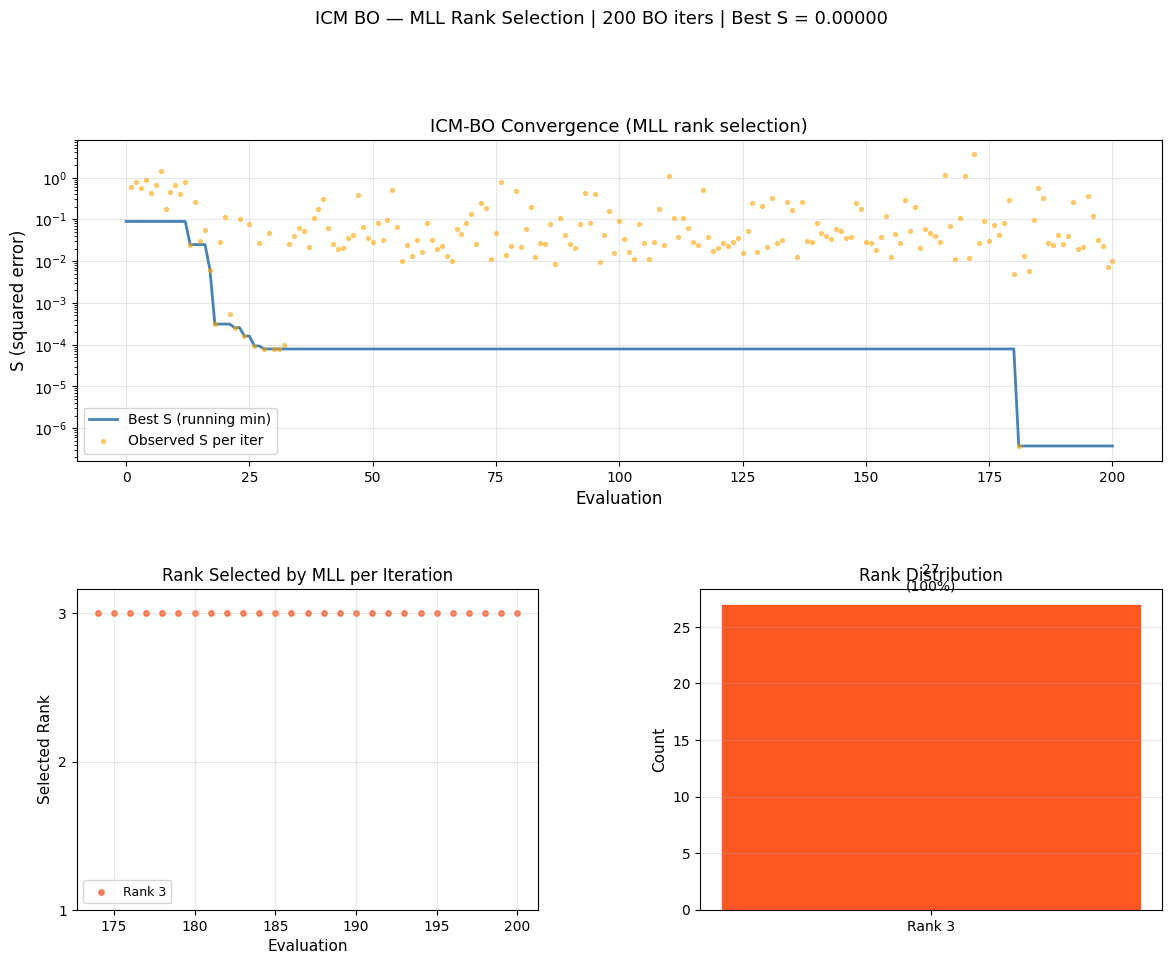

Saved: output/quickstart_icm_rankMLL_squared/ICM_rankMLL_squared/results/analysis_mll_rank.png

=== Summary ===
Initial S:    0.089236
Final best S: 0.000000
Improvement:  100.0%

Rank usage:
  Rank 3: 27 iters (100%)


In [16]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import numpy as np
from pathlib import Path

# ---- Load results ----
results_dir = Path(config["simulation_run_path"]) / BO_FOLDER / "results"
df = pd.read_csv(results_dir / "restart_1_seed-42" / "convergence.csv")

# ---- Figure layout ----
fig = plt.figure(figsize=(14, 10))
gs = gridspec.GridSpec(2, 2, figure=fig, hspace=0.4, wspace=0.35)

# --- 1. Convergence curve ---
ax1 = fig.add_subplot(gs[0, :])
ax1.plot(df["evaluation"], df["best_S_raw"], color="steelblue", lw=2, label="Best S (running min)")
ax1.scatter(df["evaluation"], df["observed_S_raw"], color="orange", s=8, alpha=0.5, label="Observed S per iter", zorder=3)
ax1.set_xlabel("Evaluation", fontsize=12)
ax1.set_ylabel("S (squared error)", fontsize=12)
ax1.set_title("ICM-BO Convergence (MLL rank selection)", fontsize=13)
ax1.set_yscale("log")
ax1.grid(True, alpha=0.3)
ax1.legend(fontsize=10)

# --- 2. Rank selected per iteration ---
ax2 = fig.add_subplot(gs[1, 0])
ranks = df["rank_selected"].dropna()
colors = {1: "#2196F3", 2: "#4CAF50", 3: "#FF5722"}
for rank_val, grp in ranks.groupby(ranks):
    ax2.scatter(df.loc[grp.index, "evaluation"], grp,
                color=colors.get(int(rank_val), "gray"),
                s=15, alpha=0.7, label=f"Rank {int(rank_val)}")
ax2.set_xlabel("Evaluation", fontsize=11)
ax2.set_ylabel("Selected Rank", fontsize=11)
ax2.set_yticks([1, 2, 3])
ax2.set_title("Rank Selected by MLL per Iteration", fontsize=12)
ax2.grid(True, alpha=0.3)
ax2.legend(fontsize=9)

# --- 3. Rank distribution bar ---
ax3 = fig.add_subplot(gs[1, 1])
rank_counts = ranks.value_counts().sort_index()
bars = ax3.bar(
    [f"Rank {int(r)}" for r in rank_counts.index],
    rank_counts.values,
    color=[colors.get(int(r), "gray") for r in rank_counts.index],
    edgecolor="white", linewidth=0.5
)
for bar, val in zip(bars, rank_counts.values):
    pct = 100 * val / rank_counts.sum()
    ax3.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
             f"{int(val)}\n({pct:.0f}%)", ha="center", va="bottom", fontsize=10)
ax3.set_ylabel("Count", fontsize=11)
ax3.set_title("Rank Distribution", fontsize=12)
ax3.grid(True, axis="y", alpha=0.3)

plt.suptitle(
    f"ICM BO \u2014 MLL Rank Selection | {len(df)-1} BO iters | "
    f"Best S = {df['best_S_raw'].min():.5f}",
    fontsize=13, y=1.01
)
plt.savefig(results_dir / "analysis_mll_rank.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved: {results_dir / 'analysis_mll_rank.png'}")

# ---- Summary stats ----
print("\n=== Summary ===")
print(f"Initial S:    {df['best_S_raw'].iloc[0]:.6f}")
print(f"Final best S: {df['best_S_raw'].min():.6f}")
print(f"Improvement:  {(1 - df['best_S_raw'].min() / df['best_S_raw'].iloc[0]) * 100:.1f}%")
print(f"\nRank usage:")
for r, cnt in rank_counts.items():
    print(f"  Rank {int(r)}: {int(cnt)} iters ({100*cnt/rank_counts.sum():.0f}%)")


# plot 

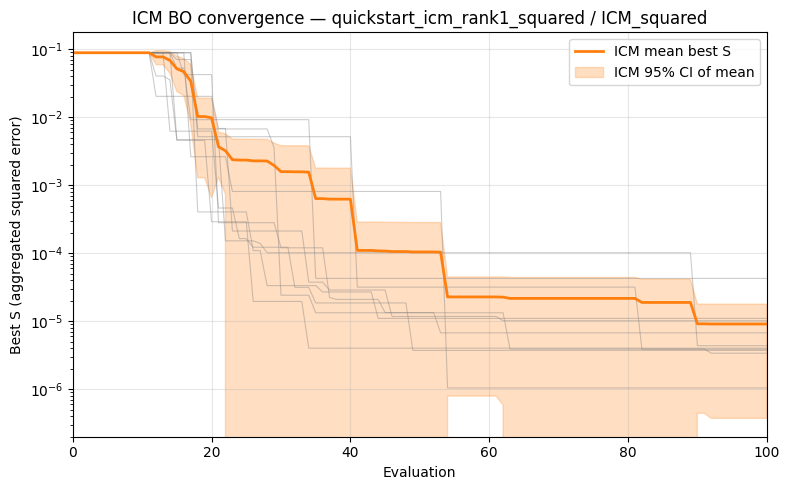

Loaded 10 restarts from: /Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/output/quickstart_icm_rank1_squared/ICM_squared/results
Restarts: ['restart_10_seed-9042', 'restart_1_seed-42', 'restart_2_seed-1042', 'restart_3_seed-2042', 'restart_4_seed-3042', 'restart_5_seed-4042', 'restart_6_seed-5042', 'restart_7_seed-6042', 'restart_8_seed-7042', 'restart_9_seed-8042']


In [14]:
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path

# --- Must match where ICM BO saved results (same as in your ICM cell) ---
network_name = config.get("network_name", "quickstart")
BO_FOLDER = "ICM_squared"

icm_run_path = Path("output") / f"{network_name}_icm_rank1_squared"
results_dir = icm_run_path / BO_FOLDER / "results"

if not results_dir.is_dir():
    raise FileNotFoundError(
        f"Missing folder: {results_dir.resolve()}\n"
        f"Run the ICM BO cell first, or change icm_run_path / network_name.\n"
        f"(config['simulation_run_path'] is currently: {config.get('simulation_run_path')!r})"
    )

# --- Load one best-S curve per restart from convergence.csv ---
histories = []
restart_labels = []

for d in sorted(results_dir.iterdir()):
    if not d.is_dir() or not d.name.startswith("restart_"):
        continue
    cf = d / "convergence.csv"
    if not cf.exists():
        continue
    df = pd.read_csv(cf)
    if "best_S_raw" in df.columns:
        y = df["best_S_raw"].tolist()
    elif "best_S_model" in df.columns:
        y = df["best_S_model"].tolist()
    else:
        continue
    histories.append(y)
    restart_labels.append(d.name)

if not histories:
    raise FileNotFoundError(f"No valid convergence.csv under {results_dir}")

n_restarts = len(histories)
min_len = min(len(h) for h in histories)
aligned_histories = np.array([h[:min_len] for h in histories], dtype=float)
iters = np.arange(min_len)

mean_curve = np.nanmean(aligned_histories, axis=0)

if n_restarts > 1:
    std_curve = np.nanstd(aligned_histories, axis=0, ddof=1)
    t_critical = stats.t.ppf(0.975, df=n_restarts - 1)
    ci_half = t_critical * (std_curve / np.sqrt(n_restarts))
else:
    ci_half = np.zeros_like(mean_curve)

fig, ax = plt.subplots(1, 1, figsize=(8, 5))

for h in histories:
    ax.plot(iters, np.array(h[:min_len], dtype=float), color="gray", alpha=0.4, linewidth=0.8)

ax.plot(iters, mean_curve, color="C1", linewidth=2, label="ICM mean best S")
ax.fill_between(
    iters,
    mean_curve - ci_half,
    mean_curve + ci_half,
    color="C1",
    alpha=0.25,
    label="ICM 95% CI of mean",
)

ax.set_xlabel("Evaluation")
ax.set_ylabel("Best S (aggregated squared error)")
ax.set_title(f"ICM BO convergence — {icm_run_path.name} / {BO_FOLDER}")
ax.set_yscale("log")
ax.set_xlim(0, min_len - 1)
ax.grid(True, alpha=0.3)
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

print(f"Loaded {n_restarts} restarts from: {results_dir.resolve()}")
print("Restarts:", restart_labels)

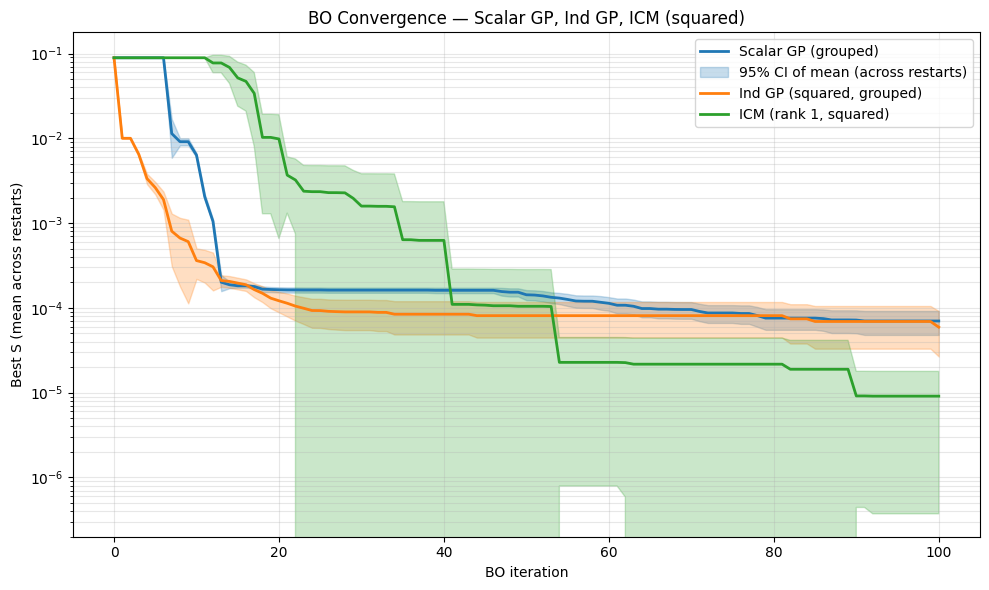

In [16]:
import matplotlib.pyplot as plt
import numpy as np
from scipy import stats
from pathlib import Path
import pandas as pd

base_path = Path("/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn")
sim_path_vanilla = base_path / "output" / "quickstart_bo_vanilla_matern-2p5"
sim_path_icm = base_path / "output" / "quickstart_icm_rank1_squared"

icm_csv = sim_path_icm / "ICM_squared" / "results" / "all_restarts_convergence.csv"

# Number of rows to plot: row 0 = after full initial design, then each BO step.
# 100 BO iterations → 1 + 100 = 101 rows (must match your all_restarts_convergence.csv files).
n_show = 101

# Old ICM runs: one row per initial eval (cummin) + BO. Set True only for those CSVs.
ICM_LEGACY_CUMMIN_CSV = False
n_init = 10  # only used if ICM_LEGACY_CUMMIN_CSV is True

methods = {
    "Scalar GP (grouped)": sim_path_vanilla / "ScalarGP" / "noise_1e-4_1" / "results" / "all_restarts_convergence.csv",
    "Ind GP (squared, grouped)": sim_path_vanilla / "indgp_bo_squared_grouped" / "noise_1e-4_1" / "results" / "all_restarts_convergence.csv",
    "ICM (rank 1, squared)": icm_csv,
}

fig, ax = plt.subplots(figsize=(10, 6))
first_method = True

for label, path in methods.items():
    if not path.exists():
        print(f"Skip {label}: not found at {path}")
        continue

    if ICM_LEGACY_CUMMIN_CSV and path.resolve() == icm_csv.resolve() and n_init > 1:
        df = pd.read_csv(path).head(n_show + n_init - 1)
        if len(df) < n_init - 1 + n_show:
            print(f"Skip {label}: need at least {n_init - 1 + n_show} rows for legacy ICM (got {len(df)})")
            continue
        df = df.iloc[n_init - 1 : n_init - 1 + n_show].reset_index(drop=True)
    else:
        df = pd.read_csv(path).head(n_show)

    restart_cols = [c for c in df.columns if c.startswith("restart_")]
    if restart_cols:
        S = df[restart_cols].to_numpy(dtype=float)
    elif "mean" in df.columns:
        S = df[["mean"]].to_numpy(dtype=float)
    elif "best_S" in df.columns:
        S = df[["best_S"]].to_numpy(dtype=float)
    else:
        print(f"Skip {label}: no restart_*, mean, or best_S column")
        continue

    n_restarts = S.shape[1]
    mean_curve = np.nanmean(S, axis=1)
    std_curve = np.nanstd(S, axis=1, ddof=1) if n_restarts > 1 else np.zeros(len(mean_curve))
    t_critical = stats.t.ppf(0.975, df=n_restarts - 1) if n_restarts > 1 else 0.0
    ci_half = (t_critical * (std_curve / np.sqrt(n_restarts))) if n_restarts > 1 else np.zeros_like(mean_curve)

    iters = np.arange(len(mean_curve))
    (line,) = ax.plot(iters, mean_curve, lw=2, label=label)

    if n_restarts > 1:
        ci_label = "95% CI of mean (across restarts)" if first_method else None
        ax.fill_between(
            iters,
            mean_curve - ci_half,
            mean_curve + ci_half,
            alpha=0.25,
            color=line.get_color(),
            label=ci_label,
        )
        first_method = False

ax.set_yscale("log")
ax.set_xlabel("BO iteration")
ax.set_ylabel("Best S (mean across restarts)")
ax.set_title("BO Convergence — Scalar GP, Ind GP, ICM (squared)")
ax.grid(True, alpha=0.3, which="both")
ax.legend()
plt.tight_layout()
plt.show()

Best OD index: 58
Best OD vector: [501.66474743 500.58582187 900.38769579 901.23784773]
GT OD vector:  [500. 500. 900. 900.]
Saved: output/quickstart_icm_rank1_squared/best_od_vs_gt.png


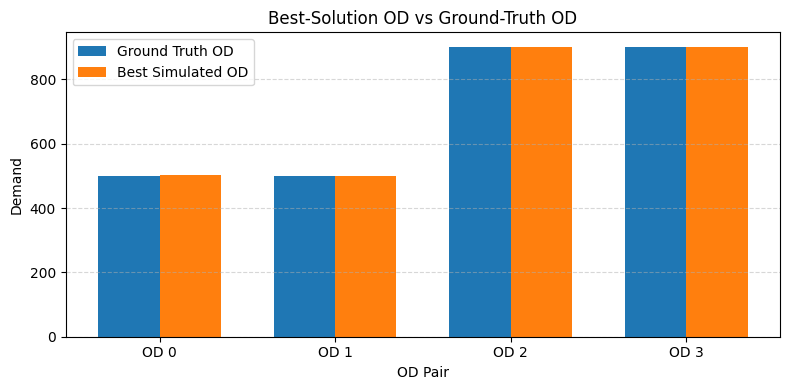

In [17]:
import numpy as np
import matplotlib.pyplot as plt

# Compute aggregated loss for all training points if not already defined
if 'S_obs_history_raw' not in locals() and 'S_obs_history_raw' not in globals():
    # Compute S_all_raw from training data
    S_all_raw = (train_Y_icm_raw * weights_uniform).sum(dim=1)
    S_obs_history_raw = S_all_raw.cpu().tolist()

best_idx = int(np.argmin(S_obs_history_raw))
best_od = train_X_icm[best_idx].cpu().numpy() 

# Ground truth OD
gt_od = gt_od_df["count"].astype(float).values  

print("Best OD index:", best_idx)
print("Best OD vector:", best_od)
print("GT OD vector: ", gt_od)

labels = [f"OD {i}" for i in range(len(gt_od))]

x = np.arange(len(gt_od))
width = 0.35

plt.figure(figsize=(8,4))
plt.bar(x - width/2, gt_od,  width, label="Ground Truth OD")
plt.bar(x + width/2, best_od, width, label="Best Simulated OD")

plt.xlabel("OD Pair")
plt.ylabel("Demand")
plt.title("Best-Solution OD vs Ground-Truth OD")
plt.xticks(x, labels)
plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()


# saving the plot 

out_dir = Path("output/quickstart_icm_rank1_squared")
out_dir.mkdir(parents=True, exist_ok=True)

fig_path = out_dir / "best_od_vs_gt.png"
plt.savefig(fig_path, dpi=200, bbox_inches="tight")
print(f"Saved: {fig_path}")
plt.show()

## eigenvalues of the task covariance 

In [18]:
with torch.no_grad():
    task = icm_model.covar_module.task_covar_module
    B = task.covar_matrix.to_dense()
    evals = torch.linalg.eigvalsh(B).flip(0)  # descending
    print(evals[:10])
    print("ratio e3/e2:", (evals[2] / evals[1]).item())

tensor([298.5421, 142.2591, 114.1781, 109.2198,  96.8049,  75.2005],
       dtype=torch.float64)
ratio e3/e2: 0.802606297625685


In [19]:
# Check the actual noise structure
likelihood = icm_model.likelihood
print(f"Likelihood type: {type(likelihood)}")
print(f"Likelihood num_tasks: {likelihood.num_tasks}")

# Check different noise attributes
print(f"\nNoise attributes:")
print(f"  noise: {likelihood.noise.shape if hasattr(likelihood.noise, 'shape') else 'scalar'}")
print(f"  noise.data: {likelihood.noise.data.shape if hasattr(likelihood.noise.data, 'shape') else 'scalar'}")

# Try accessing task-specific noise if it exists
if hasattr(likelihood, 'task_noises'):
    print(f"  task_noises: {likelihood.task_noises.shape if hasattr(likelihood.task_noises, 'shape') else 'N/A'}")
    print(f"  task_noises.data: {likelihood.task_noises.data}")

# List all attributes
print(f"\nAll likelihood attributes containing 'noise':")
for attr in dir(likelihood):
    if 'noise' in attr.lower():
        try:
            val = getattr(likelihood, attr)
            if not callable(val):
                print(f"  {attr}: {val}")
        except:
            pass

Likelihood type: <class 'gpytorch.likelihoods.multitask_gaussian_likelihood.MultitaskGaussianLikelihood'>
Likelihood num_tasks: 6

Noise attributes:
  noise: torch.Size([1])
  noise.data: torch.Size([1])
  task_noises: torch.Size([6])
  task_noises.data: tensor([1.0000e-04, 1.0000e-04, 1.0000e-04, 1.0000e-04, 1.0000e-04, 1.0000e-04],
       dtype=torch.float64)

All likelihood attributes containing 'noise':
  has_global_noise: True
  has_task_noise: True
  noise: tensor([1.0000e-04], dtype=torch.float64, grad_fn=<AddBackward0>)
  raw_noise: Parameter containing:
tensor([-349.9714], dtype=torch.float64, requires_grad=True)
  raw_task_noises: Parameter containing:
tensor([ -89.1947, -184.4218, -141.9141, -105.3705, -193.8738, -169.0462],
       dtype=torch.float64, requires_grad=True)
  task_noises: tensor([1.0000e-04, 1.0000e-04, 1.0000e-04, 1.0000e-04, 1.0000e-04, 1.0000e-04],
       dtype=torch.float64, grad_fn=<AddBackward0>)


In [20]:
# B matrix (task covariance / coregionalization)
with torch.no_grad():
    B = icm_model.covar_module.task_covar_module.covar_matrix.to_dense()
print("B shape:", B.shape)
print(B)

B shape: torch.Size([6, 6])
tensor([[113.0563, -10.0613,   3.9960,  -9.3328,   4.5346, -25.9016],
        [-10.0613, 135.5921,  -9.8833,  23.0829, -11.2156,  64.0626],
        [  3.9960,  -9.8833, 147.6223,  -9.1677,   4.4544, -25.4433],
        [ -9.3328,  23.0829,  -9.1677, 137.7752, -10.4034,  59.4238],
        [  4.5346, -11.2156,   4.4544, -10.4034,  81.0615, -28.8729],
        [-25.9016,  64.0626, -25.4433,  59.4238, -28.8729, 221.0971]],
       dtype=torch.float64)


In [21]:
with torch.no_grad():
    B = icm_model.covar_module.task_covar_module.covar_matrix.to_dense()
    d = torch.sqrt(torch.diag(B))
    corr = B / (d[:, None] * d[None, :])
print(corr)

tensor([[ 1.0000, -0.0813,  0.0309, -0.0748,  0.0474, -0.1638],
        [-0.0813,  1.0000, -0.0699,  0.1689, -0.1070,  0.3700],
        [ 0.0309, -0.0699,  1.0000, -0.0643,  0.0407, -0.1408],
        [-0.0748,  0.1689, -0.0643,  1.0000, -0.0984,  0.3405],
        [ 0.0474, -0.1070,  0.0407, -0.0984,  1.0000, -0.2157],
        [-0.1638,  0.3700, -0.1408,  0.3405, -0.2157,  1.0000]],
       dtype=torch.float64)


Saved: output/quickstart_icm_rank1_squared/B_corr_matrix.png


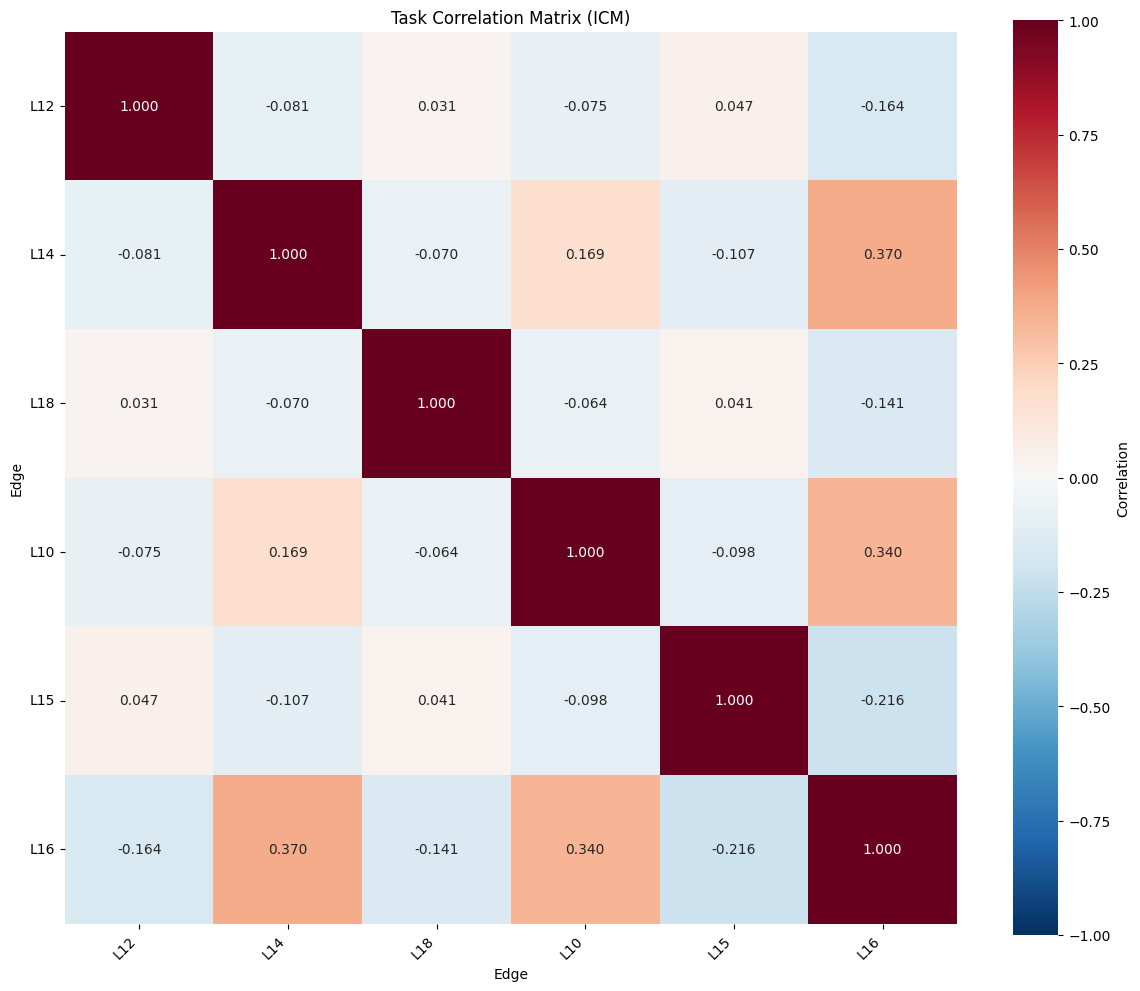

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import torch

edge_ids = grouped_edge_ids

with torch.no_grad():
    B = icm_model.covar_module.task_covar_module.covar_matrix.to_dense()
    d = torch.sqrt(torch.diag(B))
    corr = B / (d[:, None] * d[None, :])

corr_np = corr.detach().cpu().numpy()

# Create heatmap with edge IDs as labels
plt.figure(figsize=(12, 10))
sns.heatmap(
    corr_np,
    annot=True,
    fmt='.3f',
    cmap='RdBu_r',
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    cbar_kws={'label': 'Correlation'},
    xticklabels=edge_ids,  # Use actual edge IDs
    yticklabels=edge_ids,
)
plt.title('Task Correlation Matrix (ICM)')
plt.xlabel('Edge')
plt.ylabel('Edge')
plt.xticks(rotation=45, ha='right')  # Rotate labels if needed
plt.yticks(rotation=0)
plt.tight_layout()



# saving 

plt.tight_layout()

out_dir = Path("output/quickstart_icm_rank1_squared")
out_dir.mkdir(parents=True, exist_ok=True)
fig_path = out_dir / "B_corr_matrix.png"
plt.savefig(fig_path, dpi=200, bbox_inches="tight")
print(f"Saved: {fig_path}")

plt.show()


plt.show()

In [ ]:
"""
GP Hyperparameter Optimization Process:

1. ExactMarginalLogLikelihood (MLL):
   - Computes the marginal log-likelihood: log p(Y | X, θ)
   - Evaluates how well the model explains the data given current hyperparameters θ
   - Provides gradients for optimization
   
   Example:
       mll = ExactMarginalLogLikelihood(model.likelihood, model)
       current_mll = mll()  # log p(Y | X, θ_current)

2. fit_gpytorch_mll:
   - Maximizes the MLL using gradient-based optimization (L-BFGS-B)
   - Updates all hyperparameters: θ ← θ + α * ∇_θ log p(Y | X, θ)
   - Finds optimal hyperparameters: θ* = argmax_θ log p(Y | X, θ)
   
   Example:
       fit_gpytorch_mll(mll)  # Optimizes hyperparameters
       # After fitting, model has optimized θ*

Hyperparameters optimized:
   - Kernel: lengthscales ℓ, output variance σ²_f
   - Task covariance: matrix B (rank-1: parameters b)
   - Noise: per-task observation noise σ² = [σ²₁, ..., σ²_L]
   - Mean: per-task mean μ = [μ₁, ..., μ_L]
"""

'\nGP Hyperparameter Optimization Process:\n\n1. ExactMarginalLogLikelihood (MLL):\n   - Computes the marginal log-likelihood: log p(Y | X, θ)\n   - Evaluates how well the model explains the data given current hyperparameters θ\n   - Provides gradients for optimization\n\n   Example:\n       mll = ExactMarginalLogLikelihood(model.likelihood, model)\n       current_mll = mll()  # log p(Y | X, θ_current)\n\n2. fit_gpytorch_mll:\n   - Maximizes the MLL using gradient-based optimization (L-BFGS-B)\n   - Updates all hyperparameters: θ ← θ + α * ∇_θ log p(Y | X, θ)\n   - Finds optimal hyperparameters: θ* = argmax_θ log p(Y | X, θ)\n\n   Example:\n       fit_gpytorch_mll(mll)  # Optimizes hyperparameters\n       # After fitting, model has optimized θ*\n\nHyperparameters optimized:\n   - Kernel: lengthscales ℓ, output variance σ²_f\n   - Task covariance: matrix B (rank-1: parameters b)\n   - Noise: per-task observation noise σ² = [σ²₁, ..., σ²_L]\n   - Mean: per-task mean μ = [μ₁, ..., μ_L]\n'

# graphs 

In [41]:
# reloading the graph.py file
import importlib
import MOGP.graph 
importlib.reload(MOGP.graph )

<module 'MOGP.graph' from '/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/MOGP/graph.py'>

## Graph BO with regularized Laplacian kernel

Same BO loop as above but using **graph_kernel_type="regularized_laplacian"** (K = (I + γ L)⁻¹) with **learnable_gamma=True**. Results are saved under `graph_bo_regularized_laplacian` so they do not overwrite the diffusion-kernel runs.

In [17]:
# Ensure d, dtype, device exist (same as diffusion cell)
d = train_X_list.shape[1] if hasattr(train_X_list, "shape") else len(train_X_list[0])
if "dtype" not in dir():
    dtype = torch.double
if "device" not in dir():
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

od_bound_start = config.get("od_bound_start", 1)
od_bound_end = config.get("od_bound_end", 2000)
bounds = torch.stack([
    torch.full((d,), od_bound_start, dtype=dtype, device=device),
    torch.full((d,), od_bound_end, dtype=dtype, device=device),
])
bounds_norm = torch.stack([
    torch.zeros(d, dtype=dtype, device=device),
    torch.ones(d, dtype=dtype, device=device),
])

In [40]:
print(d)

4


In [19]:
# =========================
# Regularized Laplacian graph-kernel BO
# - Uniform weights
# - SQUARED (NOT cubic)
# - Saves under: output/quickstart_graph_diffusion_squared_NEW/...
# - Supports resume from last completed iteration
# =========================

import numpy as np
import torch
import pandas as pd
from pathlib import Path
import importlib
import xml.etree.ElementTree as _ET

from botorch.acquisition import ExpectedImprovement
from botorch.optim import optimize_acqf
from botorch.utils.transforms import normalize, unnormalize

import MOGP.graph
importlib.reload(MOGP.graph)

from src.utils.seed import set_seed
from src.simulation.sumo_runner import create_taz_xml, simulate_od, parse_loop_data_xml_to_pandas
from src.utils.link_flow_analysis import compute_squared_metric_per_edge
from MOGP.graph import run_graph_multitask_gp, GraphKernelAggregationModel

# -------------------------
# Required notebook variables (must already exist)
# -------------------------
required = [
    "base_path", "config", "set_seed",
    "train_X_list", "train_E_list",
    "edge_ids", "gt_od_df", "routes_df", "gt_edge_grouped",
]
missing = [k for k in required if k not in globals()]
assert not missing, f"Missing in notebook kernel: {missing}. Run the ICM setup cells first."

# -------------------------
# Config
# -------------------------
GRAPH_SIM_RUN_PATH = Path("output") / "quickstart_graph_diffusion_squared_NEW"
GRAPH_BO_SUBFOLDER = "graph_bo_regularized_laplacian_NEW"
N_RESTARTS = 5
N_BO_ITERS = 200
GRAPH_BO_BASE_SEED = config.get("SEED", 42)

raw_samples      = config.get("BO_sample_shape", 128)
num_restarts_acq = config.get("BO_num_restarts", 10)
skip_if_saved    = config.get("SKIP_RESTART_IF_SAVED", True)

dtype  = torch.double
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# -------------------------
# Build initial data
# -------------------------
train_X_init        = torch.tensor(np.array(train_X_list), dtype=dtype, device=device)
train_Y_errors_init = torch.tensor(np.array(train_E_list), dtype=dtype, device=device)

N0, d = train_X_init.shape
L     = train_Y_errors_init.shape[1]

edge_ids_list_local = edge_ids.tolist() if hasattr(edge_ids, "tolist") else list(edge_ids)

# -------------------------
# Bounds
# -------------------------
od_bound_start = float(config.get("od_bound_start", 1))
od_bound_end   = float(config.get("od_bound_end", 2000))

bounds      = torch.tensor([[od_bound_start] * d, [od_bound_end] * d], dtype=dtype, device=device)
bounds_norm = torch.tensor([[0.0] * d, [1.0] * d], dtype=dtype, device=device)

# -------------------------
# Uniform weights
# -------------------------
weights_np     = np.ones(L, dtype=float) / L
weights_flow_t = torch.tensor(weights_np, dtype=dtype, device=device)

# -------------------------
# Results directory
# -------------------------
graph_results_dir = GRAPH_SIM_RUN_PATH / GRAPH_BO_SUBFOLDER / "results"
graph_results_dir.mkdir(parents=True, exist_ok=True)


def _load_graph_iters(sim_base, n_bo_iters, train_X_init, train_Y_init,
                      best_S_init, edge_ids, weights_np, device, dtype):
    """Resume graph BO from last completed iteration saved on disk."""
    train_X = train_X_init.clone()
    train_Y = train_Y_init.clone()
    best_S  = best_S_init
    S_hist  = [best_S_init]
    start_iter = 0

    for _it in range(n_bo_iters):
        od_xml      = sim_base / f"iter_{_it}" / "od.xml"
        compare_csv = sim_base / f"iter_{_it}" / "link_measure_compare.csv"
        if not od_xml.exists() or not compare_csv.exists():
            break

        tree   = _ET.parse(str(od_xml))
        rows   = [el.attrib for el in tree.getroot().iter("tazRelation")]
        counts = pd.DataFrame(rows)["count"].astype(float).values
        _x     = torch.tensor(counts, device=device, dtype=dtype).view(1, -1)

        _df = pd.read_csv(str(compare_csv)).set_index("edge_id")
        per_edge_errors = []
        for eid in edge_ids:
            if eid in _df.index:
                gt_val  = float(_df.loc[eid, "interval_nVehContrib_gt"])
                sim_val = float(_df.loc[eid, "interval_nVehContrib_sim"])
                per_edge_errors.append(((sim_val - gt_val) / gt_val) ** 2 if gt_val > 0 else np.nan)
            else:
                per_edge_errors.append(np.nan)

        _y    = torch.tensor(per_edge_errors, device=device, dtype=dtype).view(1, -1)
        _loss = float((np.asarray(per_edge_errors) * weights_np).sum())
        if np.isnan(_loss):
            _loss = float("inf")

        train_X = torch.cat([train_X, _x], dim=0)
        train_Y = torch.cat([train_Y, _y], dim=0)
        if _loss < best_S:
            best_S = _loss
        S_hist.append(best_S)
        start_iter = _it + 1

    return train_X, train_Y, best_S, S_hist, start_iter


graph_histories = []

for r in range(N_RESTARTS):
    seed             = GRAPH_BO_BASE_SEED + r * 1000
    restart_dir      = graph_results_dir / f"restart_{r+1}_seed-{seed}"
    convergence_file = restart_dir / "convergence.csv"
    hp_log_path      = restart_dir / "hyperparameters_per_iteration.csv"

    # --- skip fully completed restarts ---
    if skip_if_saved and convergence_file.exists():
        df_prev   = pd.read_csv(convergence_file)
        S_history = df_prev["best_S"].tolist()
        while S_history and pd.isna(S_history[-1]):
            S_history.pop()
        if len(S_history) == 1 + N_BO_ITERS:
            graph_histories.append(S_history)
            print(f"\n######### Graph BO RESTART {r+1}/{N_RESTARTS} (seed={seed}) — SKIPPED #########")
            print(f"  Loaded {len(S_history)} rows, best S = {S_history[-1]:.6f}")
            continue

    set_seed(seed)
    print(f"\n######### Graph BO RESTART {r+1}/{N_RESTARTS} (seed={seed}) #########")
    restart_dir.mkdir(parents=True, exist_ok=True)

    # --- resume partially completed restart ---
    best_S_init_val = float((train_Y_errors_init * weights_flow_t).sum(dim=1).min().item())
    sim_base        = GRAPH_SIM_RUN_PATH / GRAPH_BO_SUBFOLDER / f"restart_{r+1}_seed-{seed}"

    train_X_bo, train_Y_errors_bo, best_S_raw, S_history, start_iter = _load_graph_iters(
        sim_base, N_BO_ITERS,
        train_X_init, train_Y_errors_init,
        best_S_init_val, edge_ids_list_local, weights_np,
        device, dtype,
    )

    # clear partial hp log if starting from scratch
    if start_iter == 0 and hp_log_path.exists():
        hp_log_path.unlink()

    if start_iter > 0:
        print(f"[RESUME] Loaded {start_iter} iters → resuming from iter {start_iter+1}/{N_BO_ITERS}, best S={best_S_raw:.6f}")
    else:
        print(f"[INIT] N={N0}, best S={best_S_raw:.6f}")

    for it in range(start_iter, N_BO_ITERS):
        print(f"\n--- Graph BO ITER {it+1}/{N_BO_ITERS} ---")
        train_X_norm = normalize(train_X_bo, bounds=bounds)

        # Stack: one row per (design, task)
        train_X_long, train_Y_long = [], []
        Ncur = train_Y_errors_bo.shape[0]
        for n in range(Ncur):
            for ell in range(L):
                x_row = torch.cat(
                    [train_X_norm[n:n+1],
                     torch.tensor([[float(ell)]], device=device, dtype=dtype)],
                    dim=-1,
                ).squeeze(0)
                train_X_long.append(x_row)
                train_Y_long.append(train_Y_errors_bo[n, ell])

        train_X_stacked = torch.stack(train_X_long)               # (N*L, d+1)
        train_Y_stacked = torch.stack(train_Y_long).unsqueeze(-1)  # (N*L, 1)

        graph_model, graph_mll, graph_info, fit_method = run_graph_multitask_gp(
            net_xml_path=str(config["net_xml"]),
            edge_ids=edge_ids_list_local,
            train_X=train_X_stacked,
            train_Y=train_Y_stacked,
            input_dim=d,
            adjacency_type="shared_node_weighted",
            graph_kernel_type="regularized_laplacian",
            gamma_mode="auto",
            gamma_scale=1.0,
            learnable_gamma=True,
            ignore_internal=True,
            matern_nu=2.5,
            device=device,
        )
        graph_model.eval()

        x_kern    = graph_model.covar_module.kernels[0]
        task_kern = graph_model.covar_module.kernels[1]
        outputscale_g = x_kern.outputscale.detach().item()
        ls_g          = x_kern.base_kernel.lengthscale.detach().cpu().numpy().flatten()
        noise_g       = graph_model.likelihood.noise.detach().item()
        gamma_g       = task_kern.gamma.detach().item()

        hp_row = pd.DataFrame([{
            "iteration":          it,
            "gamma":              gamma_g,
            "outputscale":        outputscale_g,
            "noise":              noise_g,
            "noise_signal_ratio": noise_g / outputscale_g,
            "fit_method":         fit_method,
            "A_density":          graph_info["A_density"],
            "n_train":            train_X_bo.shape[0],
            "best_S":             best_S_raw,
            **{f"lengthscale_dim_{i}": float(ls_g[i]) for i in range(len(ls_g))},
        }])
        hp_row.to_csv(hp_log_path, mode="a", header=not hp_log_path.exists(), index=False)
        print(f"  [HP] gamma={gamma_g:.4f}  noise={noise_g:.6f}  outputscale={outputscale_g:.6f}  fit={fit_method}")

        agg_model = GraphKernelAggregationModel(graph_model, weights_flow_t).to(device=device, dtype=dtype)
        agg_model.eval()

        best_f_ei = (train_Y_errors_bo * weights_flow_t).sum(dim=1).min()
        EI = ExpectedImprovement(model=agg_model, best_f=best_f_ei, maximize=False)
        x_next_norm, acq_val = optimize_acqf(
            EI, bounds=bounds_norm, q=1,
            num_restarts=num_restarts_acq, raw_samples=raw_samples,
        )

        x_next_real = unnormalize(x_next_norm.detach(), bounds).squeeze(0).cpu().numpy()
        x_next_real = np.clip(x_next_real, od_bound_start, od_bound_end)

        # ---- SUMO simulation ----
        sim_dir = sim_base / f"iter_{it}"
        sim_dir.mkdir(parents=True, exist_ok=True)

        od_xml        = sim_dir / "od.xml"
        prefix_output = sim_dir / "sim"

        base_od = gt_od_df.copy()
        base_od["count"] = [round(v, 1) for v in x_next_real]
        base_od = base_od.rename(columns={"fromTaz": "from", "toTaz": "to"})
        create_taz_xml(str(od_xml), base_od, config["od_duration_sec"], base_path)

        simulate_od(
            str(od_xml), str(prefix_output), base_path,
            config["net_xml"], config["taz2edge_xml"], config["additional_xml"],
            routes_df, config["sim_end_time"], config["TRIPS2ODS_OUT_STR"],
            seed=seed + it,
        )

        sim_edge_out = f"{prefix_output}_{config['EDGE_OUT_STR']}"
        curr_loop_stats, _, _ = parse_loop_data_xml_to_pandas(
            base_path, sim_edge_out, str(prefix_output), str(config["SUMO_PATH"]),
        )

        per_edge_sq = compute_squared_metric_per_edge(gt_edge_grouped, curr_loop_stats, edge_ids_list_local)
        e_next = torch.tensor(per_edge_sq, dtype=dtype, device=device)

        # save link_measure_compare.csv so resume can reload this iter
        merged = pd.merge(
            gt_edge_grouped[["edge_id", "interval_nVehContrib"]],
            curr_loop_stats[["edge_id", "interval_nVehContrib"]],
            on="edge_id", suffixes=("_gt", "_sim"),
        )
        merged.to_csv(sim_dir / "link_measure_compare.csv", index=False)

        S_next     = float((e_next * weights_flow_t).sum().item())
        best_S_raw = min(best_S_raw, S_next)
        S_history.append(best_S_raw)

        train_X_bo        = torch.cat([train_X_bo, torch.tensor(x_next_real, dtype=dtype, device=device).unsqueeze(0)], dim=0)
        train_Y_errors_bo = torch.cat([train_Y_errors_bo, e_next.unsqueeze(0)], dim=0)

        print(f"[Graph BO RL iter {it+1}/{N_BO_ITERS}] S(x_next)={S_next:.6f}, best S={best_S_raw:.6f}, EI={acq_val.item():.6f}")

        # save convergence incrementally after every iter
        pd.DataFrame({"iteration": range(len(S_history)), "best_S": S_history}).to_csv(convergence_file, index=False)

    graph_histories.append(S_history)
    print(f"\n[RESTART COMPLETE] best S={best_S_raw:.6f}")
    print(f"✓ Convergence saved: {convergence_file}")
    print(f"✓ Hyperparameters saved: {hp_log_path}")

# -------------------------
# Summary across restarts
# -------------------------
max_len = max(len(h) for h in graph_histories)
padded  = np.full((N_RESTARTS, max_len), np.nan)
for i, h in enumerate(graph_histories):
    padded[i, :len(h)] = h

mean_curve = np.nanmean(padded, axis=0)
std_curve  = np.nanstd(padded,  axis=0)

best_S_per_restart = [h[-1] for h in graph_histories]
overall_best       = min(best_S_per_restart)

print("\nGraph BO (Regularized Laplacian) COMPLETE")
print(f"Best S per restart: {[f'{s:.6f}' for s in best_S_per_restart]}")
print(f"Mean: {np.mean(best_S_per_restart):.6f} ± {np.std(best_S_per_restart):.6f}")
print(f"Overall best: {overall_best:.6f}")

pd.DataFrame({"iteration": range(len(mean_curve)), "best_S_mean": mean_curve, "best_S_std": std_curve}).to_csv(
    graph_results_dir / "convergence_mean_std.csv", index=False)

df_histories = pd.DataFrame(
    {f"restart_{i+1}": graph_histories[i] + [np.nan] * (max_len - len(graph_histories[i]))
     for i in range(N_RESTARTS)}
)
df_histories["mean"]    = mean_curve
df_histories.index.name = "iteration"
df_histories.to_csv(graph_results_dir / "all_restarts_convergence.csv")

import json
with open(graph_results_dir / "summary.json", "w") as f:
    json.dump({
        "best_S_per_restart": best_S_per_restart,
        "best_S_mean":        float(np.mean(best_S_per_restart)),
        "best_S_std":         float(np.std(best_S_per_restart)),
        "overall_best_S":     float(overall_best),
        "n_restarts":         N_RESTARTS,
        "n_bo_iters":         N_BO_ITERS,
        "n_initial":          N0,
        "graph_kernel":       "regularized_laplacian",
        "adjacency_type":     "shared_node_weighted",
        "metric":             "squared",
    }, f, indent=2)

print(f"\n✓ Saved under: {GRAPH_SIM_RUN_PATH / GRAPH_BO_SUBFOLDER}")



######### Graph BO RESTART 1/5 (seed=42) — SKIPPED #########
  Loaded 201 rows, best S = 0.000010

######### Graph BO RESTART 2/5 (seed=1042) — SKIPPED #########
  Loaded 201 rows, best S = 0.000001

######### Graph BO RESTART 3/5 (seed=2042) — SKIPPED #########
  Loaded 201 rows, best S = 0.000001

######### Graph BO RESTART 4/5 (seed=3042) #########
[RESUME] Loaded 16 iters → resuming from iter 17/200, best S=0.000117

--- Graph BO ITER 17/200 ---
  [HP] gamma=0.0045  noise=0.000103  outputscale=12.682641  fit=lbfgs
Created /Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/output/quickstart_graph_diffusion_squared_NEW/graph_bo_regularized_laplacian_NEW/restart_4_seed-3042/iter_16/od.xml
od2trips --spread.uniform --taz-files /Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/network/quickstart/taz.xml --tazrelation-files output/quickstart_graph_diffusion_squared_NEW/graph_bo_regularized_laplacian_NEW/restart_4_seed-3042/iter_16/od.xml --seed 3058 -o /Users/inesbenhamza/Desktop/Sumo_

/Users/inesbenhamza/Downloads/Sumo_od_calibration 2/env/lib/python3.12/site-packages/botorch/acquisition/analytic.py:340: NumericsWarning: ExpectedImprovement has known numerical issues that lead to suboptimal optimization performance. It is strongly recommended to simply replace

	 ExpectedImprovement 	 --> 	 LogExpectedImprovement 

instead, which fixes the issues and has the same API. See https://arxiv.org/abs/2310.20708 for details.
  legacy_ei_numerics_warning(legacy_name=type(self).__name__)


Loading net-file from '/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/network/quickstart/net.xml' ... done (2ms).
Loading additional-files from '/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/network/quickstart/additional.xml' ... done (1ms).
Loading route-files incrementally from '/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/output/quickstart_graph_diffusion_squared_NEW/graph_bo_regularized_laplacian_NEW/restart_4_seed-3042/iter_16/sim_trips.xml'
Loading done.
Simulation version 1.24.0 started with time: 0.00.
Step #57600.00 (0ms ?*RT. ?UPS, vehicles TOT 3227 ACT 0 BUF 0)                            
Simulation ended at time: 57600.00.
Reason: The final simulation step has been reached.
Performance:
 Duration: 0.63s
 Real time factor: 92012.8
 UPS: 2067956.869010
Vehicles:
 Inserted: 3227
 Running: 0
 Waiting: 0
Statistics (avg of 3227):
 RouteLength: 4346.53
 Speed: 10.85
 Duration: 401.16
 WaitingTime: 0.28
 TimeLoss: 83.91
 DepartDelay: 807.33
DijkstraRouter answered 6

/Users/inesbenhamza/Downloads/Sumo_od_calibration 2/env/lib/python3.12/site-packages/botorch/acquisition/analytic.py:340: NumericsWarning: ExpectedImprovement has known numerical issues that lead to suboptimal optimization performance. It is strongly recommended to simply replace

	 ExpectedImprovement 	 --> 	 LogExpectedImprovement 

instead, which fixes the issues and has the same API. See https://arxiv.org/abs/2310.20708 for details.
  legacy_ei_numerics_warning(legacy_name=type(self).__name__)


Running SUMO: sumo --output-prefix output/quickstart_graph_diffusion_squared_NEW/graph_bo_regularized_laplacian_NEW/restart_4_seed-3042/iter_17/sim_ --ignore-route-errors=true --net-file=/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/network/quickstart/net.xml --routes=/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/output/quickstart_graph_diffusion_squared_NEW/graph_bo_regularized_laplacian_NEW/restart_4_seed-3042/iter_17/sim_trips.xml -b 0 -e 57600 --additional-files /Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/network/quickstart/additional.xml --duration-log.statistics --xml-validation never --vehroutes routes.vehroutes.xml --verbose --no-warnings --mesosim true --seed 3059
Loading net-file from '/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/network/quickstart/net.xml' ... done (2ms).
Loading additional-files from '/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/network/quickstart/additional.xml' ... done (1ms).
Loading route-files incrementally from '/Users/ine

...

Running SUMO: sumo --output-prefix output/quickstart_graph_diffusion_squared_NEW/graph_bo_regularized_laplacian_NEW/restart_5_seed-4042/iter_197/sim_ --ignore-route-errors=true --net-file=/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/network/quickstart/net.xml --routes=/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/output/quickstart_graph_diffusion_squared_NEW/graph_bo_regularized_laplacian_NEW/restart_5_seed-4042/iter_197/sim_trips.xml -b 0 -e 57600 --additional-files /Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/network/quickstart/additional.xml --duration-log.statistics --xml-validation never --vehroutes routes.vehroutes.xml --verbose --no-warnings --mesosim true --seed 4239
Loading net-file from '/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/network/quickstart/net.xml' ... done (2ms).
Loading additional-files from '/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/network/quickstart/additional.xml' ... done (0ms).
Loading route-files incrementally from '/Users/i

/Users/inesbenhamza/Downloads/Sumo_od_calibration 2/env/lib/python3.12/site-packages/botorch/acquisition/analytic.py:340: NumericsWarning: ExpectedImprovement has known numerical issues that lead to suboptimal optimization performance. It is strongly recommended to simply replace

	 ExpectedImprovement 	 --> 	 LogExpectedImprovement 

instead, which fixes the issues and has the same API. See https://arxiv.org/abs/2310.20708 for details.
  legacy_ei_numerics_warning(legacy_name=type(self).__name__)


Running SUMO: sumo --output-prefix output/quickstart_graph_diffusion_squared_NEW/graph_bo_regularized_laplacian_NEW/restart_5_seed-4042/iter_198/sim_ --ignore-route-errors=true --net-file=/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/network/quickstart/net.xml --routes=/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/output/quickstart_graph_diffusion_squared_NEW/graph_bo_regularized_laplacian_NEW/restart_5_seed-4042/iter_198/sim_trips.xml -b 0 -e 57600 --additional-files /Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/network/quickstart/additional.xml --duration-log.statistics --xml-validation never --vehroutes routes.vehroutes.xml --verbose --no-warnings --mesosim true --seed 4240
Loading net-file from '/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/network/quickstart/net.xml' ... done (3ms).
Loading additional-files from '/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/network/quickstart/additional.xml' ... done (1ms).
Loading route-files incrementally from '/Users/i

/Users/inesbenhamza/Downloads/Sumo_od_calibration 2/env/lib/python3.12/site-packages/botorch/acquisition/analytic.py:340: NumericsWarning: ExpectedImprovement has known numerical issues that lead to suboptimal optimization performance. It is strongly recommended to simply replace

	 ExpectedImprovement 	 --> 	 LogExpectedImprovement 

instead, which fixes the issues and has the same API. See https://arxiv.org/abs/2310.20708 for details.
  legacy_ei_numerics_warning(legacy_name=type(self).__name__)


Running SUMO: sumo --output-prefix output/quickstart_graph_diffusion_squared_NEW/graph_bo_regularized_laplacian_NEW/restart_5_seed-4042/iter_199/sim_ --ignore-route-errors=true --net-file=/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/network/quickstart/net.xml --routes=/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/output/quickstart_graph_diffusion_squared_NEW/graph_bo_regularized_laplacian_NEW/restart_5_seed-4042/iter_199/sim_trips.xml -b 0 -e 57600 --additional-files /Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/network/quickstart/additional.xml --duration-log.statistics --xml-validation never --vehroutes routes.vehroutes.xml --verbose --no-warnings --mesosim true --seed 4241
Loading net-file from '/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/network/quickstart/net.xml' ... done (2ms).
Loading additional-files from '/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/network/quickstart/additional.xml' ... done (1ms).
Loading route-files incrementally from '/Users/i

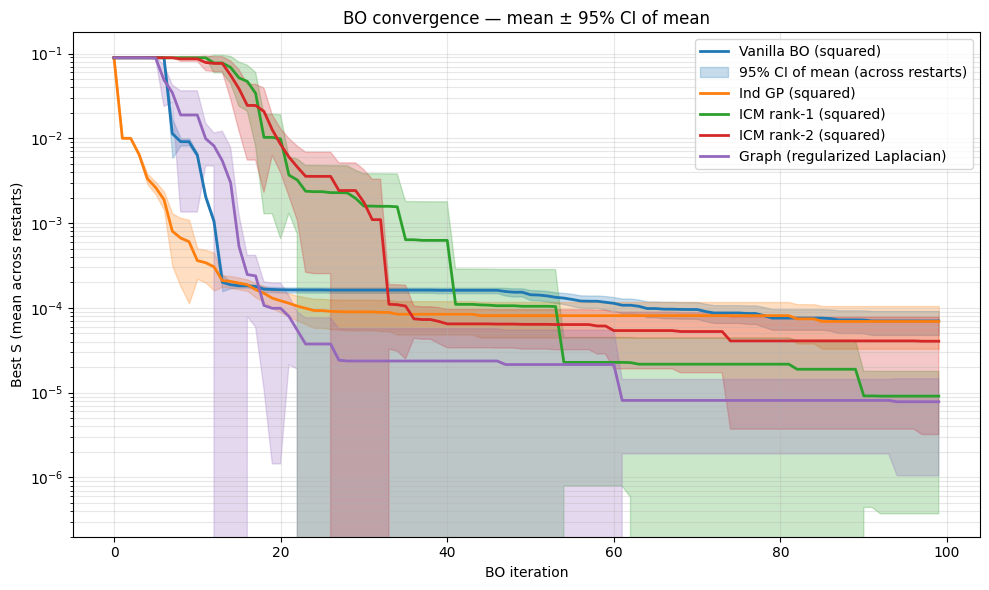

In [52]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pathlib import Path
from scipy import stats

base_path = Path("/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn")
sim_path = base_path / "output" / "quickstart_bo_vanilla_matern-2p5"
sim_path_z = base_path / "output"

n_show = 100

methods = {
    "Vanilla BO (squared)": sim_path / "ScalarGP" / "noise_1e-4_1" / "results" / "all_restarts_convergence.csv",
    "Ind GP (squared)": sim_path / "indgp_bo_squared_grouped" / "noise_1e-4_1" / "results" / "all_restarts_convergence.csv",
    "ICM rank-1 (squared)": sim_path_z / "quickstart_icm_rank1_squared" / "ICM_squared" / "results" / "all_restarts_convergence.csv",
    "ICM rank-2 (squared)": sim_path_z / "quickstart_icm_rank2_squared" / "ICM_squared" / "results" / "all_restarts_convergence.csv",
    "Graph (regularized Laplacian)": sim_path_z / "quickstart_graph_diffusion_squared" / "graph_bo_regularized_laplacian" / "results" / "all_restarts_convergence.csv",
}

fig, ax = plt.subplots(figsize=(10, 6))
first = True

for label, path in methods.items():
    if not path.exists():
        print(f"Skip {label}: not found at {path}")
        continue

    df = pd.read_csv(path).head(n_show)

    restart_cols = [c for c in df.columns if c.startswith("restart_")]
    if restart_cols:
        S = df[restart_cols].to_numpy(dtype=float)
    elif "mean" in df.columns:
        S = df[["mean"]].to_numpy(dtype=float)
    elif "best_S" in df.columns:
        S = df[["best_S"]].to_numpy(dtype=float)
    else:
        print(f"Skip {label}: no restart_*, mean, or best_S column")
        continue

    n_restarts = S.shape[1]
    mean_curve = np.nanmean(S, axis=1)
    std_curve = np.nanstd(S, axis=1, ddof=1) if n_restarts > 1 else np.zeros(len(mean_curve))
    t_crit = stats.t.ppf(0.975, df=n_restarts - 1) if n_restarts > 1 else 0.0
    half = (t_crit * (std_curve / np.sqrt(n_restarts))) if n_restarts > 1 else np.zeros_like(mean_curve)

    iters = np.arange(len(mean_curve))
    line, = ax.plot(iters, mean_curve, lw=2, label=label)
    if n_restarts > 1:
        ci_label = "95% CI of mean (across restarts)" if first else None
        ax.fill_between(
            iters,
            mean_curve - half,
            mean_curve + half,
            alpha=0.25,
            color=line.get_color(),
            label=ci_label,
        )
        first = False

ax.set_yscale("log")
ax.set_xlabel("BO iteration")
ax.set_ylabel("Best S (mean across restarts)")
ax.set_title("BO convergence — mean ± 95% CI of mean")
ax.grid(True, alpha=0.3, which="both")
ax.legend()
plt.tight_layout()
plt.show()

Graph kernels provide the largest gains in low-data regimes by leveraging spatial correlations between edges.

# graph adjacency on connection 

In [63]:
# =========================
# Regularized Laplacian graph-kernel BO
# - Uniform weights
# - SQUARED (NOT cubic)
# - Adjacency: connections (SUMO <connection> among edge_ids)
# - Saves under: .../graph_bo_regularized_laplacian_connections/
# =========================

import numpy as np
import torch
import pandas as pd
from pathlib import Path
import importlib

from botorch.acquisition import ExpectedImprovement
from botorch.optim import optimize_acqf
from botorch.utils.transforms import normalize, unnormalize

import MOGP.graph
importlib.reload(MOGP.graph)

from src.utils.seed import set_seed
from src.simulation.sumo_runner import create_taz_xml, simulate_od, parse_loop_data_xml_to_pandas
from src.utils.link_flow_analysis import compute_squared_metric_per_edge
from MOGP.graph import run_graph_multitask_gp, GraphKernelAggregationModel

# -------------------------
# Required notebook variables (must already exist)
# -------------------------
required = [
    "base_path", "config", "set_seed",
    "train_X_list", "train_E_list",
    "edge_ids", "gt_od_df", "routes_df", "gt_edge_data", "gt_edge_data",
]
missing = [k for k in required if k not in globals()]
assert not missing, f"Missing in notebook kernel: {missing}. Run the ICM setup cells that define them first."

# -------------------------
# Keep ONLY regularized laplacian
# -------------------------
GRAPH_SIM_RUN_PATH = Path("output") / "quickstart_graph_diffusion_squared"  # relative to base_path (important)
GRAPH_BO_SUBFOLDER = "graph_bo_regularized_laplacian_connections"  # shared-node: graph_bo_regularized_laplacian
N_RESTARTS = 7
N_BO_ITERS = config.get("BO_niter", 100)
GRAPH_BO_BASE_SEED = config.get("SEED", 42)

raw_samples = config.get("BO_sample_shape", 128)
num_restarts_acq = config.get("BO_num_restarts", 10)
skip_if_saved = config.get("SKIP_RESTART_IF_SAVED", True)

dtype = torch.double
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# -------------------------
# Build initial data
# -------------------------
train_X_init = torch.tensor(np.array(train_X_list), dtype=dtype, device=device)  # [N0, d]
train_Y_errors_init = torch.tensor(np.array(train_E_list), dtype=dtype, device=device)  # [N0, L]

N0, d = train_X_init.shape
L = train_Y_errors_init.shape[1]

edge_ids_list_local = edge_ids.tolist() if hasattr(edge_ids, "tolist") else list(edge_ids)

# -------------------------
# Bounds (same as ICM)
# -------------------------
od_bound_start = float(config.get("od_bound_start", 1))
od_bound_end = float(config.get("od_bound_end", 2000))

bounds = torch.tensor([[od_bound_start] * d, [od_bound_end] * d], dtype=dtype, device=device)
bounds_norm = torch.tensor([[0.0] * d, [1.0] * d], dtype=dtype, device=device)

# -------------------------
# Uniform weights (NO cubic)
# -------------------------
weights_np = np.ones(L, dtype=float) / L
weights_flow_t = torch.tensor(weights_np, dtype=dtype, device=device)

# -------------------------
# Results directory (separate)
# -------------------------
graph_results_dir = GRAPH_SIM_RUN_PATH / GRAPH_BO_SUBFOLDER / "results"
graph_results_dir.mkdir(parents=True, exist_ok=True)

graph_histories = []

for r in range(N_RESTARTS):
    seed = GRAPH_BO_BASE_SEED + r * 1000
    restart_dir = graph_results_dir / f"restart_{r+1}_seed-{seed}"
    convergence_file = restart_dir / "convergence.csv"

    if skip_if_saved and convergence_file.exists():
        S_history = pd.read_csv(convergence_file)["best_S"].tolist()
        graph_histories.append(S_history)
        print(f"\n######### Graph BO RESTART {r+1}/{N_RESTARTS} (seed={seed}) — SKIPPED #########")
        print(f"  Loaded {len(S_history)} iterations, best S = {S_history[-1]:.6f}")
        continue

    set_seed(seed)
    print(f"\n######### Graph BO RESTART {r+1}/{N_RESTARTS} (seed={seed}) #########")

    train_X_bo = train_X_init.clone()
    train_Y_errors_bo = train_Y_errors_init.clone()

    # best objective in the scalarized/original target space
    S_agg_raw = (train_Y_errors_bo * weights_flow_t).sum(dim=1)
    best_S_raw = float(S_agg_raw.min().item())
    S_history = [best_S_raw]

    for it in range(N_BO_ITERS):
        train_X_norm = normalize(train_X_bo, bounds=bounds)

        # stack: one row per (design, task); Y is raw squared-error per-edge
        train_X_long, train_Y_long = [], []
        Ncur = train_Y_errors_bo.shape[0]
        for n in range(Ncur):
            for ell in range(L):
                x_row = torch.cat(
                    [
                        train_X_norm[n : n + 1],
                        torch.tensor([[float(ell)]], device=device, dtype=dtype),
                    ],
                    dim=-1,
                ).squeeze(0)
                train_X_long.append(x_row)
                train_Y_long.append(train_Y_errors_bo[n, ell])

        train_X_stacked = torch.stack(train_X_long)                 # (N*L, d+1)
        train_Y_stacked = torch.stack(train_Y_long).unsqueeze(-1)  # (N*L, 1)

        # ---- Regularized Laplacian task kernel ----
        graph_model, graph_mll, graph_info, _ = run_graph_multitask_gp(
            net_xml_path=str(config["net_xml"]),
            edge_ids=edge_ids_list_local,
            train_X=train_X_stacked,
            train_Y=train_Y_stacked,
            input_dim=d,
            adjacency_type="connections",
            graph_kernel_type="regularized_laplacian",
            gamma_mode="auto",
            gamma_scale=1.0,
            learnable_gamma=True,
            ignore_internal=True,
            matern_nu=2.5,
            device=device,
        )
        graph_model.eval()

        agg_model = GraphKernelAggregationModel(graph_model, weights_flow_t).to(device=device, dtype=dtype)
        agg_model.eval()

        # best_f for EI in the same scalarized/original space
        best_f_ei = (train_Y_errors_bo * weights_flow_t).sum(dim=1).min()

        EI = ExpectedImprovement(model=agg_model, best_f=best_f_ei, maximize=False)
        x_next_norm, acq_val = optimize_acqf(
            EI,
            bounds=bounds_norm,
            q=1,
            num_restarts=num_restarts_acq,
            raw_samples=raw_samples,
        )

        x_next_real = unnormalize(x_next_norm.detach(), bounds).squeeze(0).cpu().numpy()
        x_next_real = np.clip(x_next_real, od_bound_start, od_bound_end)

        # -------------------------
        # Run SUMO + evaluate squared per-edge
        # -------------------------
        sim_dir = GRAPH_SIM_RUN_PATH / GRAPH_BO_SUBFOLDER / f"restart_{r+1}_seed-{seed}" / f"iter_{it}"
        sim_dir.mkdir(parents=True, exist_ok=True)

        od_xml = sim_dir / "od.xml"          # relative path under base_path
        prefix_output = sim_dir / "sim"    # relative path under base_path

        base_od = gt_od_df.copy()
        base_od["count"] = [round(v, 1) for v in x_next_real]
        base_od = base_od.rename(columns={"fromTaz": "from", "toTaz": "to"})

        # IMPORTANT: create_taz_xml prepends base_dir, so keep od_xml relative
        create_taz_xml(str(od_xml), base_od, config["od_duration_sec"], base_path)

        simulate_od(
            str(od_xml),
            str(prefix_output),
            base_path,  # your notebook variable
            config["net_xml"],
            config["taz2edge_xml"],
            config["additional_xml"],
            routes_df,
            config["sim_end_time"],
            config["TRIPS2ODS_OUT_STR"],
            seed=seed + it,          # IMPORTANT: keep only seed
            # sim_start_time is intentionally NOT passed -> defaults to 0
        )

        sim_edge_out = f"{prefix_output}_{config['EDGE_OUT_STR']}"
        curr_loop_stats, _, _ = parse_loop_data_xml_to_pandas(
            base_path,
            sim_edge_out,
            str(prefix_output),
            str(config["SUMO_PATH"]),
        )

        per_edge_sq = compute_squared_metric_per_edge(gt_edge_data, curr_loop_stats, edge_ids_list_local)
        e_next = torch.tensor(per_edge_sq, dtype=dtype, device=device)

        S_next = float((e_next * weights_flow_t).sum().item())
        best_S_raw = min(best_S_raw, S_next)
        S_history.append(best_S_raw)

        # update training sets
        train_X_bo = torch.cat(
            [train_X_bo, torch.tensor(x_next_real, dtype=dtype, device=device).unsqueeze(0)],
            dim=0,
        )
        train_Y_errors_bo = torch.cat([train_Y_errors_bo, e_next.unsqueeze(0)], dim=0)

        print(f"[Graph BO RL squared iter {it+1}/{N_BO_ITERS}] S(x_next)={S_next:.6f}, best S={best_S_raw:.6f}, EI={acq_val.item():.6f}")

    graph_histories.append(S_history)
    restart_dir.mkdir(parents=True, exist_ok=True)
    pd.DataFrame({"iteration": range(len(S_history)), "best_S": S_history}).to_csv(convergence_file, index=False)

# -------------------------
# Summary across restarts
# -------------------------
max_len = max(len(h) for h in graph_histories)
padded = np.full((N_RESTARTS, max_len), np.nan)
for i, h in enumerate(graph_histories):
    padded[i, :len(h)] = h

mean_curve = np.nanmean(padded, axis=0)
df_histories = pd.DataFrame(
    {f"restart_{i+1}": graph_histories[i] + [np.nan] * (max_len - len(graph_histories[i])) for i in range(N_RESTARTS)}
)
df_histories["mean"] = mean_curve
df_histories.index.name = "iteration"
df_histories.to_csv(graph_results_dir / "all_restarts_convergence.csv")

print(f"\n✓ Saved under: {GRAPH_SIM_RUN_PATH / GRAPH_BO_SUBFOLDER}")
print(f"  - {graph_results_dir / 'all_restarts_convergence.csv'}")


######### Graph BO RESTART 1/7 (seed=42) — SKIPPED #########
  Loaded 101 iterations, best S = 0.000021

######### Graph BO RESTART 2/7 (seed=1042) — SKIPPED #########
  Loaded 101 iterations, best S = 0.000029

######### Graph BO RESTART 3/7 (seed=2042) — SKIPPED #########
  Loaded 101 iterations, best S = 0.000002

######### Graph BO RESTART 4/7 (seed=3042) — SKIPPED #########
  Loaded 101 iterations, best S = 0.000018

######### Graph BO RESTART 5/7 (seed=4042) — SKIPPED #########
  Loaded 101 iterations, best S = 0.000004

######### Graph BO RESTART 6/7 (seed=5042) — SKIPPED #########
  Loaded 101 iterations, best S = 0.000010

######### Graph BO RESTART 7/7 (seed=6042) #########
Created /Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/output/quickstart_graph_diffusion_squared/graph_bo_regularized_laplacian_connections/restart_7_seed-6042/iter_0/od.xml
od2trips --spread.uniform --taz-files /Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/network/quickstart/taz.xml --tazrelatio

/Users/inesbenhamza/Downloads/Sumo_od_calibration 2/env/lib/python3.12/site-packages/botorch/acquisition/analytic.py:340: NumericsWarning: ExpectedImprovement has known numerical issues that lead to suboptimal optimization performance. It is strongly recommended to simply replace

	 ExpectedImprovement 	 --> 	 LogExpectedImprovement 

instead, which fixes the issues and has the same API. See https://arxiv.org/abs/2310.20708 for details.
  legacy_ei_numerics_warning(legacy_name=type(self).__name__)


Running SUMO: sumo --output-prefix output/quickstart_graph_diffusion_squared/graph_bo_regularized_laplacian_connections/restart_7_seed-6042/iter_0/sim_ --ignore-route-errors=true --net-file=/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/network/quickstart/net.xml --routes=/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/output/quickstart_graph_diffusion_squared/graph_bo_regularized_laplacian_connections/restart_7_seed-6042/iter_0/sim_trips.xml -b 0 -e 57600 --additional-files /Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/network/quickstart/additional.xml --duration-log.statistics --xml-validation never --vehroutes routes.vehroutes.xml --verbose --no-warnings --mesosim true --seed 6042
Loading net-file from '/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/network/quickstart/net.xml' ... done (2ms).
Loading additional-files from '/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/network/quickstart/additional.xml' ... done (2ms).
Loading route-files incrementally from '/Use

/Users/inesbenhamza/Downloads/Sumo_od_calibration 2/env/lib/python3.12/site-packages/botorch/acquisition/analytic.py:340: NumericsWarning: ExpectedImprovement has known numerical issues that lead to suboptimal optimization performance. It is strongly recommended to simply replace

	 ExpectedImprovement 	 --> 	 LogExpectedImprovement 

instead, which fixes the issues and has the same API. See https://arxiv.org/abs/2310.20708 for details.
  legacy_ei_numerics_warning(legacy_name=type(self).__name__)


Created /Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/output/quickstart_graph_diffusion_squared/graph_bo_regularized_laplacian_connections/restart_7_seed-6042/iter_1/od.xml
od2trips --spread.uniform --taz-files /Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/network/quickstart/taz.xml --tazrelation-files output/quickstart_graph_diffusion_squared/graph_bo_regularized_laplacian_connections/restart_7_seed-6042/iter_1/od.xml --seed 6043 -o /Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/output/quickstart_graph_diffusion_squared/graph_bo_regularized_laplacian_connections/restart_7_seed-6042/iter_1/sim_trips_beforeRteUpdates.xml
Running SUMO: sumo --output-prefix output/quickstart_graph_diffusion_squared/graph_bo_regularized_laplacian_connections/restart_7_seed-6042/iter_1/sim_ --ignore-route-errors=true --net-file=/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/network/quickstart/net.xml --routes=/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/output/quickstart_graph_diffus

...

Created /Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/output/quickstart_graph_diffusion_squared/graph_bo_regularized_laplacian_connections/restart_7_seed-6042/iter_97/od.xml
od2trips --spread.uniform --taz-files /Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/network/quickstart/taz.xml --tazrelation-files output/quickstart_graph_diffusion_squared/graph_bo_regularized_laplacian_connections/restart_7_seed-6042/iter_97/od.xml --seed 6139 -o /Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/output/quickstart_graph_diffusion_squared/graph_bo_regularized_laplacian_connections/restart_7_seed-6042/iter_97/sim_trips_beforeRteUpdates.xml
Running SUMO: sumo --output-prefix output/quickstart_graph_diffusion_squared/graph_bo_regularized_laplacian_connections/restart_7_seed-6042/iter_97/sim_ --ignore-route-errors=true --net-file=/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/network/quickstart/net.xml --routes=/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/output/quickstart_graph_di

/Users/inesbenhamza/Downloads/Sumo_od_calibration 2/env/lib/python3.12/site-packages/botorch/acquisition/analytic.py:340: NumericsWarning: ExpectedImprovement has known numerical issues that lead to suboptimal optimization performance. It is strongly recommended to simply replace

	 ExpectedImprovement 	 --> 	 LogExpectedImprovement 

instead, which fixes the issues and has the same API. See https://arxiv.org/abs/2310.20708 for details.
  legacy_ei_numerics_warning(legacy_name=type(self).__name__)


Created /Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/output/quickstart_graph_diffusion_squared/graph_bo_regularized_laplacian_connections/restart_7_seed-6042/iter_98/od.xml
od2trips --spread.uniform --taz-files /Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/network/quickstart/taz.xml --tazrelation-files output/quickstart_graph_diffusion_squared/graph_bo_regularized_laplacian_connections/restart_7_seed-6042/iter_98/od.xml --seed 6140 -o /Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/output/quickstart_graph_diffusion_squared/graph_bo_regularized_laplacian_connections/restart_7_seed-6042/iter_98/sim_trips_beforeRteUpdates.xml
Running SUMO: sumo --output-prefix output/quickstart_graph_diffusion_squared/graph_bo_regularized_laplacian_connections/restart_7_seed-6042/iter_98/sim_ --ignore-route-errors=true --net-file=/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/network/quickstart/net.xml --routes=/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/output/quickstart_graph_di

/Users/inesbenhamza/Downloads/Sumo_od_calibration 2/env/lib/python3.12/site-packages/botorch/acquisition/analytic.py:340: NumericsWarning: ExpectedImprovement has known numerical issues that lead to suboptimal optimization performance. It is strongly recommended to simply replace

	 ExpectedImprovement 	 --> 	 LogExpectedImprovement 

instead, which fixes the issues and has the same API. See https://arxiv.org/abs/2310.20708 for details.
  legacy_ei_numerics_warning(legacy_name=type(self).__name__)


Created /Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/output/quickstart_graph_diffusion_squared/graph_bo_regularized_laplacian_connections/restart_7_seed-6042/iter_99/od.xml
od2trips --spread.uniform --taz-files /Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/network/quickstart/taz.xml --tazrelation-files output/quickstart_graph_diffusion_squared/graph_bo_regularized_laplacian_connections/restart_7_seed-6042/iter_99/od.xml --seed 6141 -o /Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/output/quickstart_graph_diffusion_squared/graph_bo_regularized_laplacian_connections/restart_7_seed-6042/iter_99/sim_trips_beforeRteUpdates.xml
Running SUMO: sumo --output-prefix output/quickstart_graph_diffusion_squared/graph_bo_regularized_laplacian_connections/restart_7_seed-6042/iter_99/sim_ --ignore-route-errors=true --net-file=/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/network/quickstart/net.xml --routes=/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/output/quickstart_graph_di

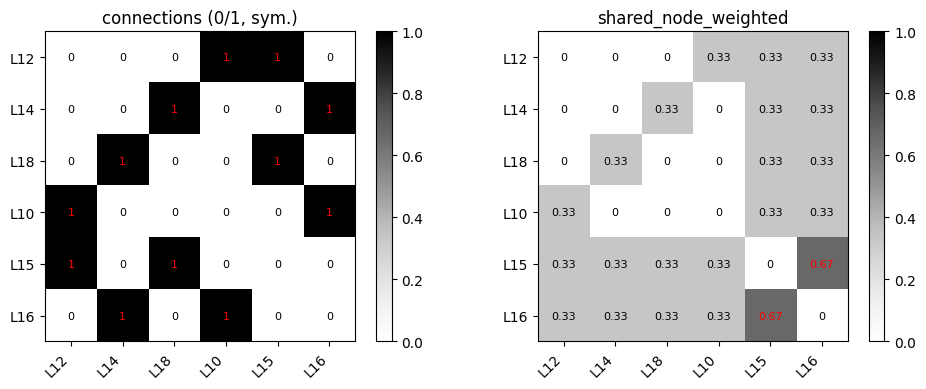

In [64]:
import numpy as np
import matplotlib.pyplot as plt
import torch
from MOGP.graph import adjacency_from_connections, adjacency_by_shared_node_weighted

net = str(config["net_xml"])
edges = edge_ids.tolist() if hasattr(edge_ids, "tolist") else list(edge_ids)

A_conn = adjacency_from_connections(net, edges, ignore_internal=True, undirected=True).cpu().numpy()
A_shared = adjacency_by_shared_node_weighted(net, edges, ignore_internal=True).cpu().numpy()

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, A, title in zip(
    axes,
    [A_conn, A_shared],
    ["connections (0/1, sym.)", "shared_node_weighted"],
):
    im = ax.imshow(A, cmap="Greys", vmin=0, vmax=max(A_shared.max(), 1.0))
    ax.set_xticks(np.arange(len(edges)))
    ax.set_yticks(np.arange(len(edges)))
    ax.set_xticklabels(edges, rotation=45, ha="right")
    ax.set_yticklabels(edges)
    ax.set_title(title)
    # optional: annotate small matrices
    if A.shape[0] <= 10:
        for i in range(A.shape[0]):
            for j in range(A.shape[1]):
                ax.text(j, i, f"{A[i, j]:.2g}", ha="center", va="center", fontsize=8, color="red" if A[i,j] > 0.5 else "black")
    plt.colorbar(im, ax=ax, fraction=0.046)

plt.tight_layout()
plt.show()

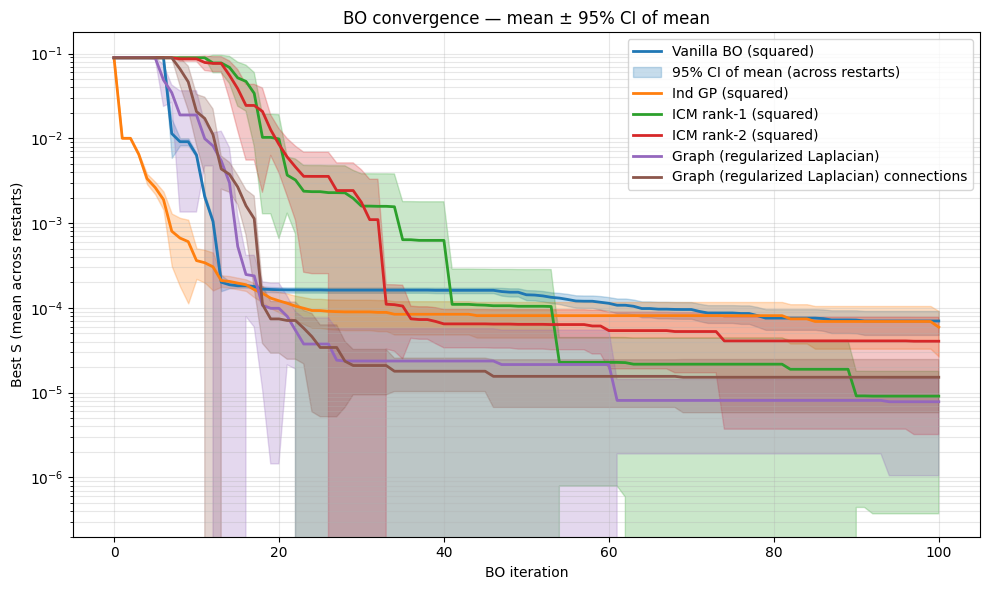

In [67]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pathlib import Path
from scipy import stats

base_path = Path("/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn")
sim_path = base_path / "output" / "quickstart_bo_vanilla_matern-2p5"
sim_path_z = base_path / "output"

n_show = 101

methods = {
    "Vanilla BO (squared)": sim_path / "ScalarGP" / "noise_1e-4_1" / "results" / "all_restarts_convergence.csv",
    "Ind GP (squared)": sim_path / "indgp_bo_squared_grouped" / "noise_1e-4_1" / "results" / "all_restarts_convergence.csv",
    "ICM rank-1 (squared)": sim_path_z / "quickstart_icm_rank1_squared" / "ICM_squared" / "results" / "all_restarts_convergence.csv",
    "ICM rank-2 (squared)": sim_path_z / "quickstart_icm_rank2_squared" / "ICM_squared" / "results" / "all_restarts_convergence.csv",
    "Graph (regularized Laplacian)": sim_path_z / "quickstart_graph_diffusion_squared" / "graph_bo_regularized_laplacian" / "results" / "all_restarts_convergence.csv",
    "Graph (regularized Laplacian) connections": sim_path_z / "quickstart_graph_diffusion_squared" / "graph_bo_regularized_laplacian_connections" / "results" / "all_restarts_convergence.csv",
}

fig, ax = plt.subplots(figsize=(10, 6))
first = True

for label, path in methods.items():
    if not path.exists():
        print(f"Skip {label}: not found at {path}")
        continue

    df = pd.read_csv(path).head(n_show)

    restart_cols = [c for c in df.columns if c.startswith("restart_")]
    if restart_cols:
        S = df[restart_cols].to_numpy(dtype=float)
    elif "mean" in df.columns:
        S = df[["mean"]].to_numpy(dtype=float)
    elif "best_S" in df.columns:
        S = df[["best_S"]].to_numpy(dtype=float)
    else:
        print(f"Skip {label}: no restart_*, mean, or best_S column")
        continue

    n_restarts = S.shape[1]
    mean_curve = np.nanmean(S, axis=1)
    std_curve = np.nanstd(S, axis=1, ddof=1) if n_restarts > 1 else np.zeros(len(mean_curve))
    t_crit = stats.t.ppf(0.975, df=n_restarts - 1) if n_restarts > 1 else 0.0
    half = (t_crit * (std_curve / np.sqrt(n_restarts))) if n_restarts > 1 else np.zeros_like(mean_curve)

    iters = np.arange(len(mean_curve))
    line, = ax.plot(iters, mean_curve, lw=2, label=label)
    if n_restarts > 1:
        ci_label = "95% CI of mean (across restarts)" if first else None
        ax.fill_between(
            iters,
            mean_curve - half,
            mean_curve + half,
            alpha=0.25,
            color=line.get_color(),
            label=ci_label,
        )
        first = False

ax.set_yscale("log")
ax.set_xlabel("BO iteration")
ax.set_ylabel("Best S (mean across restarts)")
ax.set_title("BO convergence — mean ± 95% CI of mean")
ax.grid(True, alpha=0.3, which="both")
ax.legend()
plt.tight_layout()
plt.show()

# diffusion kernel 

In [10]:
# =========================
# Diffusion graph-kernel BO
# - Uniform weights
# - SQUARED (NOT cubic)
# - Adjacency: connections (SUMO <connection> among edge_ids)
# - Saves under: .../graph_bo_diffusion_connections/
# - Supports resume from last completed iteration
# =========================

import numpy as np
import torch
import pandas as pd
from pathlib import Path
import importlib
import xml.etree.ElementTree as _ET
import json

from botorch.acquisition import ExpectedImprovement
from botorch.optim import optimize_acqf
from botorch.utils.transforms import normalize, unnormalize

import MOGP.graph
importlib.reload(MOGP.graph)

from src.utils.seed import set_seed
from src.simulation.sumo_runner import create_taz_xml, simulate_od, parse_loop_data_xml_to_pandas
from src.utils.link_flow_analysis import compute_squared_metric_per_edge
from MOGP.graph import run_graph_multitask_gp, GraphKernelAggregationModel

# -------------------------
# Required notebook variables
# -------------------------
required = [
    "base_path", "config", "set_seed",
    "train_X_list", "train_E_list",
    "edge_ids", "gt_od_df", "routes_df", "gt_edge_grouped",
]
missing = [k for k in required if k not in globals()]
assert not missing, f"Missing in notebook kernel: {missing}. Run the ICM setup cells first."

# -------------------------
# Config
# -------------------------
GRAPH_SIM_RUN_PATH = Path("output") / "quickstart_graph_diffusion_squared_NEW"
GRAPH_BO_SUBFOLDER = "graph_bo_diffusion_shared_node"
N_RESTARTS = 5
N_BO_ITERS = 200
GRAPH_BO_BASE_SEED = config.get("SEED", 42)

raw_samples      = config.get("BO_sample_shape", 128)
num_restarts_acq = config.get("BO_num_restarts", 10)
skip_if_saved    = config.get("SKIP_RESTART_IF_SAVED", True)

dtype  = torch.double
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# -------------------------
# Build initial data
# -------------------------
train_X_init        = torch.tensor(np.array(train_X_list), dtype=dtype, device=device)
train_Y_errors_init = torch.tensor(np.array(train_E_list), dtype=dtype, device=device)

N0, d = train_X_init.shape
L     = train_Y_errors_init.shape[1]

edge_ids_list_local = edge_ids.tolist() if hasattr(edge_ids, "tolist") else list(edge_ids)

# -------------------------
# Bounds
# -------------------------
od_bound_start = float(config.get("od_bound_start", 1))
od_bound_end   = float(config.get("od_bound_end", 2000))

bounds      = torch.tensor([[od_bound_start] * d, [od_bound_end] * d], dtype=dtype, device=device)
bounds_norm = torch.tensor([[0.0] * d, [1.0] * d], dtype=dtype, device=device)

# -------------------------
# Uniform weights
# -------------------------
weights_np     = np.ones(L, dtype=float) / L
weights_flow_t = torch.tensor(weights_np, dtype=dtype, device=device)

# -------------------------
# Results directory
# -------------------------
graph_results_dir = GRAPH_SIM_RUN_PATH / GRAPH_BO_SUBFOLDER / "results"
graph_results_dir.mkdir(parents=True, exist_ok=True)


def _load_graph_iters(sim_base, n_bo_iters, train_X_init, train_Y_init,
                      best_S_init, edge_ids, weights_np, device, dtype):
    """Resume graph BO from last completed iteration saved on disk."""
    train_X    = train_X_init.clone()
    train_Y    = train_Y_init.clone()
    best_S     = best_S_init
    S_hist     = [best_S_init]
    start_iter = 0

    for _it in range(n_bo_iters):
        od_xml      = sim_base / f"iter_{_it}" / "od.xml"
        compare_csv = sim_base / f"iter_{_it}" / "link_measure_compare.csv"
        if not od_xml.exists() or not compare_csv.exists():
            break

        tree   = _ET.parse(str(od_xml))
        rows   = [el.attrib for el in tree.getroot().iter("tazRelation")]
        counts = pd.DataFrame(rows)["count"].astype(float).values
        _x     = torch.tensor(counts, device=device, dtype=dtype).view(1, -1)

        _df = pd.read_csv(str(compare_csv)).set_index("edge_id")
        per_edge_errors = []
        for eid in edge_ids:
            if eid in _df.index:
                gt_val  = float(_df.loc[eid, "interval_nVehContrib_gt"])
                sim_val = float(_df.loc[eid, "interval_nVehContrib_sim"])
                per_edge_errors.append(((sim_val - gt_val) / gt_val) ** 2 if gt_val > 0 else np.nan)
            else:
                per_edge_errors.append(np.nan)

        _loss = float((np.asarray(per_edge_errors) * weights_np).sum())
        if np.isnan(_loss):
            _loss = float("inf")

        _y = torch.tensor(per_edge_errors, device=device, dtype=dtype).view(1, -1)
        train_X = torch.cat([train_X, _x], dim=0)
        train_Y = torch.cat([train_Y, _y], dim=0)
        if _loss < best_S:
            best_S = _loss
        S_hist.append(best_S)
        start_iter = _it + 1

    return train_X, train_Y, best_S, S_hist, start_iter


graph_histories = []

for r in range(N_RESTARTS):
    seed             = GRAPH_BO_BASE_SEED + r * 1000
    restart_dir      = graph_results_dir / f"restart_{r+1}_seed-{seed}"
    convergence_file = restart_dir / "convergence.csv"
    hp_log_path      = restart_dir / "hyperparameters_per_iteration.csv"

    # --- skip fully completed restarts ---
    if skip_if_saved and convergence_file.exists():
        df_prev   = pd.read_csv(convergence_file)
        S_history = df_prev["best_S"].tolist()
        while S_history and pd.isna(S_history[-1]):
            S_history.pop()
        if len(S_history) == 1 + N_BO_ITERS:
            graph_histories.append(S_history)
            print(f"\n######### Graph BO (diffusion) RESTART {r+1}/{N_RESTARTS} (seed={seed}) — SKIPPED #########")
            print(f"  Loaded {len(S_history)} rows, best S = {S_history[-1]:.6f}")
            continue

    set_seed(seed)
    print(f"\n######### Graph BO (diffusion) RESTART {r+1}/{N_RESTARTS} (seed={seed}) #########")
    restart_dir.mkdir(parents=True, exist_ok=True)

    # --- resume partially completed restart ---
    best_S_init_val = float((train_Y_errors_init * weights_flow_t).sum(dim=1).min().item())
    sim_base        = GRAPH_SIM_RUN_PATH / GRAPH_BO_SUBFOLDER / f"restart_{r+1}_seed-{seed}"

    train_X_bo, train_Y_errors_bo, best_S_raw, S_history, start_iter = _load_graph_iters(
        sim_base, N_BO_ITERS,
        train_X_init, train_Y_errors_init,
        best_S_init_val, edge_ids_list_local, weights_np,
        device, dtype,
    )

    if start_iter == 0 and hp_log_path.exists():
        hp_log_path.unlink()

    if start_iter > 0:
        print(f"[RESUME] Loaded {start_iter} iters → resuming from iter {start_iter+1}/{N_BO_ITERS}, best S={best_S_raw:.6f}")
    else:
        print(f"[INIT] N={N0}, best S={best_S_raw:.6f}")

    for it in range(start_iter, N_BO_ITERS):
        print(f"\n--- Graph BO (diffusion) ITER {it+1}/{N_BO_ITERS} ---")
        train_X_norm = normalize(train_X_bo, bounds=bounds)

        train_X_long, train_Y_long = [], []
        Ncur = train_Y_errors_bo.shape[0]
        for n in range(Ncur):
            for ell in range(L):
                x_row = torch.cat(
                    [train_X_norm[n:n+1],
                     torch.tensor([[float(ell)]], device=device, dtype=dtype)],
                    dim=-1,
                ).squeeze(0)
                train_X_long.append(x_row)
                train_Y_long.append(train_Y_errors_bo[n, ell])

        train_X_stacked = torch.stack(train_X_long)
        train_Y_stacked = torch.stack(train_Y_long).unsqueeze(-1)

        graph_model, graph_mll, graph_info, fit_method = run_graph_multitask_gp(
            net_xml_path=str(config["net_xml"]),
            edge_ids=edge_ids_list_local,
            train_X=train_X_stacked,
            train_Y=train_Y_stacked,
            input_dim=d,
            adjacency_type="shared_node_weighted",
            graph_kernel_type="diffusion",
            tau_mode="auto",
            tau_scale=1.0,
            learnable_tau=True,
            ignore_internal=True,
            matern_nu=2.5,
            device=device,
        )
        graph_model.eval()

        # --- log hyperparameters ---
        x_kern        = graph_model.covar_module.kernels[0]
        task_kern     = graph_model.covar_module.kernels[1]
        outputscale_g = x_kern.outputscale.detach().item()
        ls_g          = x_kern.base_kernel.lengthscale.detach().cpu().numpy().flatten()
        noise_g       = graph_model.likelihood.noise.detach().item()
        tau_g         = task_kern.tau.detach().item()

        hp_row = pd.DataFrame([{
            "iteration":          it,
            "tau":                tau_g,
            "outputscale":        outputscale_g,
            "noise":              noise_g,
            "noise_signal_ratio": noise_g / outputscale_g,
            "fit_method":         fit_method,
            "A_density":          graph_info["A_density"],
            "n_train":            train_X_bo.shape[0],
            "best_S":             best_S_raw,
            **{f"lengthscale_dim_{i}": float(ls_g[i]) for i in range(len(ls_g))},
        }])
        hp_row.to_csv(hp_log_path, mode="a", header=not hp_log_path.exists(), index=False)
        print(f"  [HP] tau={tau_g:.4f}  noise={noise_g:.6f}  outputscale={outputscale_g:.6f}  fit={fit_method}")

        agg_model = GraphKernelAggregationModel(graph_model, weights_flow_t).to(device=device, dtype=dtype)
        agg_model.eval()

        best_f_ei = (train_Y_errors_bo * weights_flow_t).sum(dim=1).min()
        EI = ExpectedImprovement(model=agg_model, best_f=best_f_ei, maximize=False)
        x_next_norm, acq_val = optimize_acqf(
            EI, bounds=bounds_norm, q=1,
            num_restarts=num_restarts_acq, raw_samples=raw_samples,
        )

        x_next_real = unnormalize(x_next_norm.detach(), bounds).squeeze(0).cpu().numpy()
        x_next_real = np.clip(x_next_real, od_bound_start, od_bound_end)

        sim_dir       = sim_base / f"iter_{it}"
        sim_dir.mkdir(parents=True, exist_ok=True)
        od_xml        = sim_dir / "od.xml"
        prefix_output = sim_dir / "sim"

        base_od = gt_od_df.copy()
        base_od["count"] = [round(v, 1) for v in x_next_real]
        base_od = base_od.rename(columns={"fromTaz": "from", "toTaz": "to"})
        create_taz_xml(str(od_xml), base_od, config["od_duration_sec"], base_path)

        simulate_od(
            str(od_xml), str(prefix_output), base_path,
            config["net_xml"], config["taz2edge_xml"], config["additional_xml"],
            routes_df, config["sim_end_time"], config["TRIPS2ODS_OUT_STR"],
            seed=seed + it,
        )

        sim_edge_out = f"{prefix_output}_{config['EDGE_OUT_STR']}"
        curr_loop_stats, _, _ = parse_loop_data_xml_to_pandas(
            base_path, sim_edge_out, str(prefix_output), str(config["SUMO_PATH"]),
        )

        per_edge_sq = compute_squared_metric_per_edge(gt_edge_grouped, curr_loop_stats, edge_ids_list_local)
        e_next = torch.tensor(per_edge_sq, dtype=dtype, device=device)

        merged = pd.merge(
            gt_edge_grouped[["edge_id", "interval_nVehContrib"]],
            curr_loop_stats[["edge_id", "interval_nVehContrib"]],
            on="edge_id", suffixes=("_gt", "_sim"),
        )
        merged.to_csv(sim_dir / "link_measure_compare.csv", index=False)

        S_next     = float((e_next * weights_flow_t).sum().item())
        best_S_raw = min(best_S_raw, S_next)
        S_history.append(best_S_raw)

        train_X_bo        = torch.cat([train_X_bo, torch.tensor(x_next_real, dtype=dtype, device=device).unsqueeze(0)], dim=0)
        train_Y_errors_bo = torch.cat([train_Y_errors_bo, e_next.unsqueeze(0)], dim=0)

        print(f"[Graph BO diffusion iter {it+1}/{N_BO_ITERS}] S(x_next)={S_next:.6f}, best S={best_S_raw:.6f}, EI={acq_val.item():.6f}")

        # incremental convergence save
        pd.DataFrame({"iteration": range(len(S_history)), "best_S": S_history}).to_csv(convergence_file, index=False)

    graph_histories.append(S_history)
    print(f"\n[RESTART COMPLETE] best S={best_S_raw:.6f}")
    print(f"✓ Convergence saved: {convergence_file}")
    print(f"✓ Hyperparameters saved: {hp_log_path}")

# -------------------------
# Summary across restarts
# -------------------------
max_len = max(len(h) for h in graph_histories)
padded  = np.full((N_RESTARTS, max_len), np.nan)
for i, h in enumerate(graph_histories):
    padded[i, :len(h)] = h

mean_curve = np.nanmean(padded, axis=0)
std_curve  = np.nanstd(padded,  axis=0)

best_S_per_restart = [h[-1] for h in graph_histories]
overall_best       = min(best_S_per_restart)

print("\nGraph BO (Diffusion) COMPLETE")
print(f"Best S per restart: {[f'{s:.6f}' for s in best_S_per_restart]}")
print(f"Mean: {np.mean(best_S_per_restart):.6f} ± {np.std(best_S_per_restart):.6f}")
print(f"Overall best: {overall_best:.6f}")

pd.DataFrame({"iteration": range(len(mean_curve)), "best_S_mean": mean_curve, "best_S_std": std_curve}).to_csv(
    graph_results_dir / "convergence_mean_std.csv", index=False)

df_histories = pd.DataFrame(
    {f"restart_{i+1}": graph_histories[i] + [np.nan] * (max_len - len(graph_histories[i]))
     for i in range(N_RESTARTS)}
)
df_histories["mean"]    = mean_curve
df_histories.index.name = "iteration"
df_histories.to_csv(graph_results_dir / "all_restarts_convergence.csv")

with open(graph_results_dir / "summary.json", "w") as f:
    json.dump({
        "best_S_per_restart": best_S_per_restart,
        "best_S_mean":        float(np.mean(best_S_per_restart)),
        "best_S_std":         float(np.std(best_S_per_restart)),
        "overall_best_S":     float(overall_best),
        "n_restarts":         N_RESTARTS,
        "n_bo_iters":         N_BO_ITERS,
        "n_initial":          N0,
        "graph_kernel":       "diffusion",
        "adjacency_type":     "shared_node_weighted",
        "metric":             "squared",
    }, f, indent=2)

print(f"\n✓ Saved under: {GRAPH_SIM_RUN_PATH / GRAPH_BO_SUBFOLDER}")



######### Graph BO (diffusion) RESTART 1/5 (seed=42) #########
[RESUME] Loaded 143 iters → resuming from iter 144/200, best S=0.000000

--- Graph BO (diffusion) ITER 144/200 ---
  [HP] tau=0.0000  noise=0.000100  outputscale=259.997769  fit=lbfgs
Created /Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/output/quickstart_graph_diffusion_squared_NEW/graph_bo_diffusion_shared_node/restart_1_seed-42/iter_143/od.xml
od2trips --spread.uniform --taz-files /Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/network/quickstart/taz.xml --tazrelation-files output/quickstart_graph_diffusion_squared_NEW/graph_bo_diffusion_shared_node/restart_1_seed-42/iter_143/od.xml --seed 185 -o /Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/output/quickstart_graph_diffusion_squared_NEW/graph_bo_diffusion_shared_node/restart_1_seed-42/iter_143/sim_trips_beforeRteUpdates.xml
Running SUMO: sumo --output-prefix output/quickstart_graph_diffusion_squared_NEW/graph_bo_diffusion_shared_node/restart_1_seed-42/iter_

/Users/inesbenhamza/Downloads/Sumo_od_calibration 2/env/lib/python3.12/site-packages/botorch/acquisition/analytic.py:340: NumericsWarning: ExpectedImprovement has known numerical issues that lead to suboptimal optimization performance. It is strongly recommended to simply replace

	 ExpectedImprovement 	 --> 	 LogExpectedImprovement 

instead, which fixes the issues and has the same API. See https://arxiv.org/abs/2310.20708 for details.
  legacy_ei_numerics_warning(legacy_name=type(self).__name__)


Loading net-file from '/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/network/quickstart/net.xml' ... done (2ms).
Loading additional-files from '/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/network/quickstart/additional.xml' ... done (2ms).
Loading route-files incrementally from '/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/output/quickstart_graph_diffusion_squared_NEW/graph_bo_diffusion_shared_node/restart_1_seed-42/iter_143/sim_trips.xml'
Loading done.
Simulation version 1.24.0 started with time: 0.00.
Step #57600.00 (0ms ?*RT. ?UPS, vehicles TOT 3987 ACT 0 BUF 0)                            
Simulation ended at time: 57600.00.
Reason: The final simulation step has been reached.
Performance:
 Duration: 0.91s
 Real time factor: 63646.4
 UPS: 1997850.828729
Vehicles:
 Inserted: 3987
 Running: 0
 Waiting: 0
Statistics (avg of 3987):
 RouteLength: 4267.90
 Speed: 9.66
 Duration: 453.49
 WaitingTime: 0.47
 TimeLoss: 142.13
 DepartDelay: 987.00
DijkstraRouter answered 7826 q

/Users/inesbenhamza/Downloads/Sumo_od_calibration 2/env/lib/python3.12/site-packages/botorch/acquisition/analytic.py:340: NumericsWarning: ExpectedImprovement has known numerical issues that lead to suboptimal optimization performance. It is strongly recommended to simply replace

	 ExpectedImprovement 	 --> 	 LogExpectedImprovement 

instead, which fixes the issues and has the same API. See https://arxiv.org/abs/2310.20708 for details.
  legacy_ei_numerics_warning(legacy_name=type(self).__name__)


Loading net-file from '/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/network/quickstart/net.xml' ... done (2ms).
Loading additional-files from '/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/network/quickstart/additional.xml' ... done (0ms).
Loading route-files incrementally from '/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/output/quickstart_graph_diffusion_squared_NEW/graph_bo_diffusion_shared_node/restart_1_seed-42/iter_144/sim_trips.xml'
Loading done.
Simulation version 1.24.0 started with time: 0.00.
Step #57600.00 (0ms ?*RT. ?UPS, vehicles TOT 2777 ACT 0 BUF 0)                            
Simulation ended at time: 57600.00.
Reason: The final simulation step has been reached.
Performance:
 Duration: 0.63s
 Real time factor: 91139.2
 UPS: 1829756.329114
Vehicles:
 Inserted: 2777
 Running: 0
 Waiting: 0
Statistics (avg of 2777):
 RouteLength: 4458.37
 Speed: 10.72
 Duration: 416.42
 WaitingTime: 0.36
 TimeLoss: 91.83
 DepartDelay: 800.93
DijkstraRouter answered 5375 q

...

Running SUMO: sumo --output-prefix output/quickstart_graph_diffusion_squared_NEW/graph_bo_diffusion_shared_node/restart_5_seed-4042/iter_197/sim_ --ignore-route-errors=true --net-file=/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/network/quickstart/net.xml --routes=/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/output/quickstart_graph_diffusion_squared_NEW/graph_bo_diffusion_shared_node/restart_5_seed-4042/iter_197/sim_trips.xml -b 0 -e 57600 --additional-files /Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/network/quickstart/additional.xml --duration-log.statistics --xml-validation never --vehroutes routes.vehroutes.xml --verbose --no-warnings --mesosim true --seed 4239
Loading net-file from '/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/network/quickstart/net.xml' ... done (2ms).
Loading additional-files from '/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/network/quickstart/additional.xml' ... done (1ms).
Loading route-files incrementally from '/Users/inesbenha

/Users/inesbenhamza/Downloads/Sumo_od_calibration 2/env/lib/python3.12/site-packages/botorch/acquisition/analytic.py:340: NumericsWarning: ExpectedImprovement has known numerical issues that lead to suboptimal optimization performance. It is strongly recommended to simply replace

	 ExpectedImprovement 	 --> 	 LogExpectedImprovement 

instead, which fixes the issues and has the same API. See https://arxiv.org/abs/2310.20708 for details.
  legacy_ei_numerics_warning(legacy_name=type(self).__name__)


Loading net-file from '/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/network/quickstart/net.xml' ... done (2ms).
Loading additional-files from '/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/network/quickstart/additional.xml' ... done (0ms).
Loading route-files incrementally from '/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/output/quickstart_graph_diffusion_squared_NEW/graph_bo_diffusion_shared_node/restart_5_seed-4042/iter_198/sim_trips.xml'
Loading done.
Simulation version 1.24.0 started with time: 0.00.
Step #57600.00 (0ms ?*RT. ?UPS, vehicles TOT 2638 ACT 0 BUF 0)                            
Simulation ended at time: 57600.00.
Reason: The final simulation step has been reached.
Performance:
 Duration: 0.50s
 Real time factor: 115431
 UPS: 2300567.134269
Vehicles:
 Inserted: 2638
 Running: 0
 Waiting: 0
Statistics (avg of 2638):
 RouteLength: 4650.37
 Speed: 10.72
 Duration: 435.17
 WaitingTime: 0.37
 TimeLoss: 98.27
 DepartDelay: 644.18
DijkstraRouter answered 5104 

/Users/inesbenhamza/Downloads/Sumo_od_calibration 2/env/lib/python3.12/site-packages/botorch/acquisition/analytic.py:340: NumericsWarning: ExpectedImprovement has known numerical issues that lead to suboptimal optimization performance. It is strongly recommended to simply replace

	 ExpectedImprovement 	 --> 	 LogExpectedImprovement 

instead, which fixes the issues and has the same API. See https://arxiv.org/abs/2310.20708 for details.
  legacy_ei_numerics_warning(legacy_name=type(self).__name__)


Loading net-file from '/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/network/quickstart/net.xml' ... done (2ms).
Loading additional-files from '/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/network/quickstart/additional.xml' ... done (1ms).
Loading route-files incrementally from '/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/output/quickstart_graph_diffusion_squared_NEW/graph_bo_diffusion_shared_node/restart_5_seed-4042/iter_199/sim_trips.xml'
Loading done.
Simulation version 1.24.0 started with time: 0.00.
Step #57600.00 (0ms ?*RT. ?UPS, vehicles TOT 2424 ACT 0 BUF 0)                            
Simulation ended at time: 57600.00.
Reason: The final simulation step has been reached.
Performance:
 Duration: 0.43s
 Real time factor: 133953
 UPS: 2346913.953488
Vehicles:
 Inserted: 2424
 Running: 0
 Waiting: 0
Statistics (avg of 2424):
 RouteLength: 4454.31
 Speed: 10.73
 Duration: 416.32
 WaitingTime: 0.37
 TimeLoss: 92.21
 DepartDelay: 528.01
DijkstraRouter answered 4684 

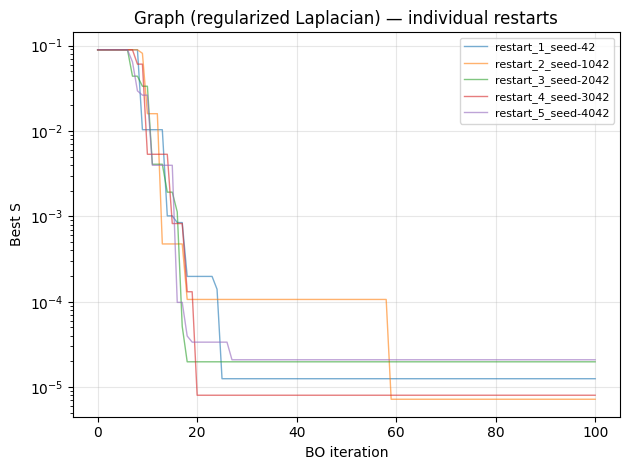

In [70]:
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path

base_path = Path("/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn")
results_dir = base_path / "output" / "quickstart_graph_diffusion_squared" / "graph_bo_diffusion_connections" / "results"

fig, ax = plt.subplots()
ax.set_yscale("log")
ax.set_xlabel("BO iteration")
ax.set_ylabel("Best S")

restart_dirs = sorted([d for d in results_dir.iterdir() if d.is_dir() and d.name.startswith("restart_")])

for d in restart_dirs:
    cf = d / "convergence.csv"
    if not cf.exists():
        continue
    df = pd.read_csv(cf)
    ax.plot(df["iteration"], df["best_S"], alpha=0.6, linewidth=1, label=d.name)

ax.legend(loc="best", fontsize=8)
ax.grid(True, alpha=0.3)
ax.set_title("Graph (regularized Laplacian) — individual restarts")
plt.tight_layout()
plt.show()

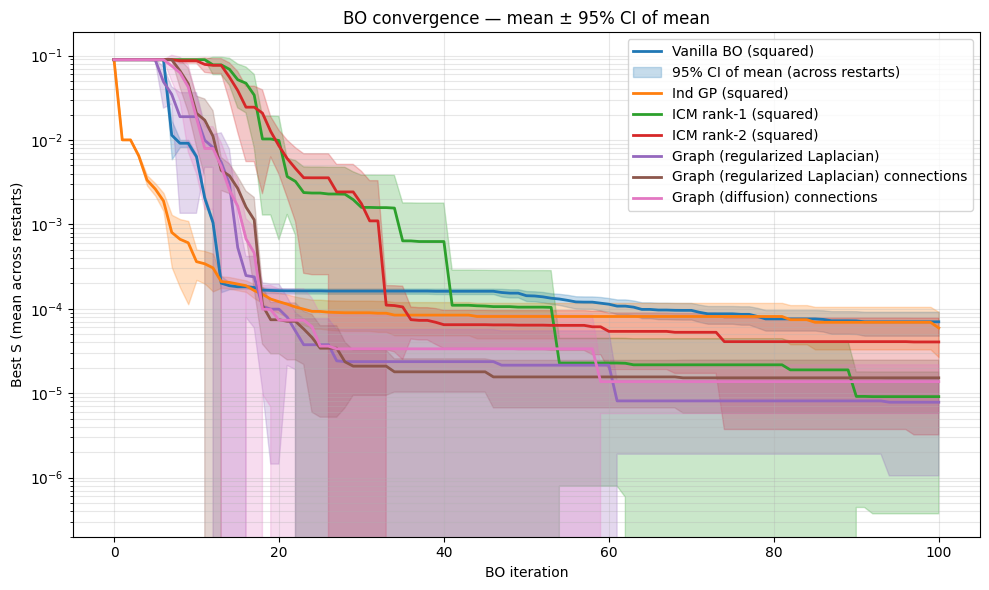

In [69]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pathlib import Path
from scipy import stats

base_path = Path("/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn")
sim_path = base_path / "output" / "quickstart_bo_vanilla_matern-2p5"
sim_path_z = base_path / "output"

n_show = 101

methods = {
    "Vanilla BO (squared)": sim_path / "ScalarGP" / "noise_1e-4_1" / "results" / "all_restarts_convergence.csv",
    "Ind GP (squared)": sim_path / "indgp_bo_squared_grouped" / "noise_1e-4_1" / "results" / "all_restarts_convergence.csv",
    "ICM rank-1 (squared)": sim_path_z / "quickstart_icm_rank1_squared" / "ICM_squared" / "results" / "all_restarts_convergence.csv",
    "ICM rank-2 (squared)": sim_path_z / "quickstart_icm_rank2_squared" / "ICM_squared" / "results" / "all_restarts_convergence.csv",
    "Graph (regularized Laplacian)": sim_path_z / "quickstart_graph_diffusion_squared" / "graph_bo_regularized_laplacian" / "results" / "all_restarts_convergence.csv",
    "Graph (regularized Laplacian) connections": sim_path_z / "quickstart_graph_diffusion_squared" / "graph_bo_regularized_laplacian_connections" / "results" / "all_restarts_convergence.csv",
    "Graph (diffusion) connections": sim_path_z / "quickstart_graph_diffusion_squared" / "graph_bo_diffusion_connections" / "results" / "all_restarts_convergence.csv",
}

fig, ax = plt.subplots(figsize=(10, 6))
first = True

for label, path in methods.items():
    if not path.exists():
        print(f"Skip {label}: not found at {path}")
        continue

    df = pd.read_csv(path).head(n_show)

    restart_cols = [c for c in df.columns if c.startswith("restart_")]
    if restart_cols:
        S = df[restart_cols].to_numpy(dtype=float)
    elif "mean" in df.columns:
        S = df[["mean"]].to_numpy(dtype=float)
    elif "best_S" in df.columns:
        S = df[["best_S"]].to_numpy(dtype=float)
    else:
        print(f"Skip {label}: no restart_*, mean, or best_S column")
        continue

    n_restarts = S.shape[1]
    mean_curve = np.nanmean(S, axis=1)
    std_curve = np.nanstd(S, axis=1, ddof=1) if n_restarts > 1 else np.zeros(len(mean_curve))
    t_crit = stats.t.ppf(0.975, df=n_restarts - 1) if n_restarts > 1 else 0.0
    half = (t_crit * (std_curve / np.sqrt(n_restarts))) if n_restarts > 1 else np.zeros_like(mean_curve)

    iters = np.arange(len(mean_curve))
    line, = ax.plot(iters, mean_curve, lw=2, label=label)
    if n_restarts > 1:
        ci_label = "95% CI of mean (across restarts)" if first else None
        ax.fill_between(
            iters,
            mean_curve - half,
            mean_curve + half,
            alpha=0.25,
            color=line.get_color(),
            label=ci_label,
        )
        first = False

ax.set_yscale("log")
ax.set_xlabel("BO iteration")
ax.set_ylabel("Best S (mean across restarts)")
ax.set_title("BO convergence — mean ± 95% CI of mean")
ax.grid(True, alpha=0.3, which="both")
ax.legend()
plt.tight_layout()
plt.show()

In [71]:
import torch
from MOGP.graph import (
    adjacency_by_shared_node_weighted,
    diffusion_kernel_from_adjacency_eigh,
    regularized_laplacian_kernel_from_adjacency_eigh,
    random_walk_kernel_from_adjacency_eigh,
)
from src.utils.edge_transition_matrix import QUICKSTART_EDGE_GROUPS

edge_ids = sorted(QUICKSTART_EDGE_GROUPS.keys())
A = adjacency_by_shared_node_weighted("network/quickstart/net.xml", edge_ids)

print("=== kernel matrices ===")
for name, fn, kwargs in [
    ("diffusion", diffusion_kernel_from_adjacency_eigh, {}),
    ("reg_lap", regularized_laplacian_kernel_from_adjacency_eigh, {}),
    ("rw p=1", random_walk_kernel_from_adjacency_eigh, {"p": 1}),
    ("rw p=2", random_walk_kernel_from_adjacency_eigh, {"p": 2}),
    ("rw p=3", random_walk_kernel_from_adjacency_eigh, {"p": 3}),
]:
    K = fn(A, **kwargs)[0]
    evals = torch.linalg.eigvalsh(K)
    print(
        f"{name:12s}: diag_mean={K.diagonal().mean():.4f}  "
        f"min={K.min():.4f}  max={K.max():.4f}  "
        f"min_eval={evals.min():.2e}  "
        f"sym={torch.allclose(K, K.T, atol=1e-10)}"
    )

print("\n=== spectrum_k sanity ===")
K_full = diffusion_kernel_from_adjacency_eigh(A)[0]
K_k6 = diffusion_kernel_from_adjacency_eigh(A, spectrum_k=6)[0]
print(f"diffusion full vs k=6: max_diff={(K_full - K_k6).abs().max():.2e}")

ImportError: cannot import name 'random_walk_kernel_from_adjacency_eigh' from 'MOGP.graph' (/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/MOGP/graph.py)